In [1]:
import copy
import os
import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    StratifiedShuffleSplit,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler,
)
from sklearn.svm import LinearSVC
from sklearn.utils.validation import check_is_fitted
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm

Задача проекта — предсказание выхода клиента в дефолт по кредиту.<br>
Целевая переменная `flag` принимает значение 1 при факте ухода в дефолт.<br>
Значение ROC-AUC на тестовом датасете должно быть не менее 0.75.

# 1 Анализ данных

In [2]:
data_path = 'train_data/'  # путь до данных на компьютере
# Формат имён файлов: train_data/train_data_N.pq

file_paths = sorted(
    [os.path.join(data_path, filename)
     for filename in os.listdir(data_path)
     if filename.startswith('train_data_')],
    key=lambda x: int(x.split('_')[-1].split('.')[0])
)

Проверим, встречаются ли одинаковые `id` в разных Parquet-файлах, чтобы выяснить, можно ли независимо агрегировать каждый файл по заявкам.

In [3]:
print(f'Поиск повторов id в разных файлах\n'
      f'Заодно смотрим пропуски и дубликаты\n')

all_data_len = 0
idx_set_prev = set()
for path in file_paths:
    df = pd.read_parquet(path)
    all_data_len += len(df)
    idx_set_curr = set(df['id'])
    txt = '- все значения id новые'
    if idx_set_prev & idx_set_curr:
        txt = '- есть повторяющиеся id'
    txt += f', пропусков {df.isna().sum().sum()}'
    txt += f', дубликатов строк {df.duplicated().sum()}'
    print(path, txt)
    idx_set_prev |= idx_set_curr

del df, idx_set_prev, idx_set_curr  # освобождаем память
print(f'\nОбщее количество строк во всех файлах: {all_data_len:,}'.replace(',', ' '))

Поиск повторов id в разных файлах
Заодно смотрим пропуски и дубликаты

train_data/train_data_0.pq - все значения id новые, пропусков 0, дубликатов строк 0
train_data/train_data_1.pq - все значения id новые, пропусков 0, дубликатов строк 0
train_data/train_data_2.pq - все значения id новые, пропусков 0, дубликатов строк 0
train_data/train_data_3.pq - все значения id новые, пропусков 0, дубликатов строк 0
train_data/train_data_4.pq - все значения id новые, пропусков 0, дубликатов строк 0
train_data/train_data_5.pq - все значения id новые, пропусков 0, дубликатов строк 0
train_data/train_data_6.pq - все значения id новые, пропусков 0, дубликатов строк 0
train_data/train_data_7.pq - все значения id новые, пропусков 0, дубликатов строк 0
train_data/train_data_8.pq - все значения id новые, пропусков 0, дубликатов строк 0
train_data/train_data_9.pq - все значения id новые, пропусков 0, дубликатов строк 0
train_data/train_data_10.pq - все значения id новые, пропусков 0, дубликатов строк 0
trai

Одинаковые `id` в разных файлах не встречаются. Поэтому каждый файл можно независимо агрегировать по `id`, а полученные части затем объединить без повторной агрегации. Пропуски и полные дубликаты строк также не обнаружены.

In [4]:
df = pd.read_parquet(file_paths[0])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1974724 entries, 0 to 1974723
Data columns (total 61 columns):
 #   Column                         Dtype
---  ------                         -----
 0   id                             int64
 1   rn                             int64
 2   pre_since_opened               int64
 3   pre_since_confirmed            int64
 4   pre_pterm                      int64
 5   pre_fterm                      int64
 6   pre_till_pclose                int64
 7   pre_till_fclose                int64
 8   pre_loans_credit_limit         int64
 9   pre_loans_next_pay_summ        int64
 10  pre_loans_outstanding          int64
 11  pre_loans_total_overdue        int64
 12  pre_loans_max_overdue_sum      int64
 13  pre_loans_credit_cost_rate     int64
 14  pre_loans5                     int64
 15  pre_loans530                   int64
 16  pre_loans3060                  int64
 17  pre_loans6090                  int64
 18  pre_loans90                    int64
 19  

Первый файл содержит 1 974 724 строки и 61 столбец. Каждая строка описывает отдельный кредитный продукт, поэтому одной заявке (`id`) может соответствовать несколько строк. Все значения хранятся в целочисленном виде, однако по смыслу признаки относятся к разным типам.

**Атрибуты данных**

•	id - идентификатор заявки. Заявки пронумерованы так, что большему номеру соответствует более поздняя дата заявки.<br>
•	rn - порядковый номер кредитного продукта в кредитной истории. Большему номеру соответствует продукт с более поздней датой открытия.<br>
•	pre_since_opened - количество дней с даты открытия кредита до даты сбора данных (бинаризовано*).<br>
•	pre_since_confirmed - количество дней с даты подтверждения информации по кредиту до даты сбора данных (бинаризовано*).<br>
•	pre_pterm - плановое количество дней с даты открытия кредита до даты закрытия (бинаризовано*).<br>
•	pre_fterm - фактическое количество дней с даты открытия кредита до даты закрытия (бинаризовано*).<br>
•	pre_till_pclose - плановое количество дней с даты сбора данных до даты закрытия кредита (бинаризовано*).<br>
•	pre_till_fclose - фактическое количество дней с даты сбора данных до даты закрытия кредита (бинаризовано*).<br>
•	pre_loans_credit_limit - кредитный лимит (бинаризовано*).<br>
•	pre_loans_next_pay_summ - сумма следующего платежа по кредиту (бинаризовано*).<br>
•	pre_loans_outstanding - оставшаяся невыплаченная сумма кредита (бинаризовано*).<br>
•	pre_loans_total_overdue - текущая просроченная задолженность (бинаризовано*).<br>
•	pre_loans_max_overdue_sum - максимальная просроченная задолженность (бинаризовано*).<br>
•	pre_loans_credit_cost_rate - полная стоимость кредита (бинаризовано*).<br>
•	pre_loans5 - число просрочек до 5 дней (бинаризовано*).<br>
•	pre_loans530 - число просрочек от 5 до 30 дней (бинаризовано*).<br>
•	pre_loans3060 - число просрочек от 30 до 60 дней (бинаризовано*).<br>
•	pre_loans6090 - число просрочек от 60 до 90 дней (бинаризовано*).<br>
•	pre_loans90 - число просрочек более чем на 90 дней (бинаризовано*).<br>
•	is_zero_loans5 - флаг: нет просрочек до 5 дней.<br>
•	is_zero_loans530 - флаг: нет просрочек от 5 до 30 дней.<br>
•	is_zero_loans3060 - флаг: нет просрочек от 30 до 60 дней.<br>
•	is_zero_loans6090 - флаг: нет просрочек от 60 до 90 дней.<br>
•	is_zero_loans90 - флаг: нет просрочек более чем на 90 дней.<br>
•	pre_util - отношение оставшейся невыплаченной суммы кредита к кредитному лимиту (бинаризовано*).<br>
•	pre_over2limit - отношение текущей просроченной задолженности к кредитному лимиту (бинаризовано*).<br>
•	pre_maxover2limit - отношение максимальной просроченной задолженности к кредитному лимиту (бинаризовано*).<br>
•	is_zero_util - флаг: отношение оставшейся невыплаченной суммы кредита к кредитному лимиту равно 0.<br>
•	is_zero_over2limit - флаг: отношение текущей просроченной задолженности к кредитному лимиту равно 0.<br>
•	is_zero_maxover2limit - флаг: отношение максимальной просроченной задолженности к кредитному лимиту равно 0.<br>
•	enc_paym_{0 ... N} - статусы ежемесячных платежей за последние N месяцев (закодировано**).<br>
•	enc_loans_account_holder_type - тип отношения к кредиту (закодировано**).<br>
•	enc_loans_credit_status - статус кредита (закодировано**).<br>
•	enc_loans_credit_type - тип кредита (закодировано**).<br>
•	enc_loans_account_cur - валюта кредита (закодировано**).<br>
•	pclose_flag - флаг: плановое количество дней с даты открытия кредита до даты закрытия не определено.<br>
•	fclose_flag - флаг: фактическое количество дней с даты открытия кредита до даты закрытия не определено.<br><br>


*\* область значений поля разбивается на N непересекающихся промежутков. Каждому промежутку случайным образом назначается уникальный номер от 0 до N-1, а значение поля заменяется номером промежутка, которому оно принадлежит*

*\*\* каждому уникальному значению поля случайным образом ставится в соответствие уникальный номер от 0 до K, значение поля заменяется номером этого значения*

В наборе данных присутствуют признаки двух типов: категориальные и бинарные. Чтобы получить общее представление о содержании многочисленных категориальных признаков, объединим их в смысловые группы.

In [5]:
# Временные характеристики кредитных продуктов
time_columns = [
    'pre_since_opened',
    'pre_since_confirmed',
    'pre_pterm',
    'pre_fterm',
    'pre_till_pclose',
    'pre_till_fclose',
]

# Финансовые характеристики кредитных продуктов
financial_columns = [
    'pre_loans_credit_limit',
    'pre_loans_next_pay_summ',
    'pre_loans_outstanding',
    'pre_loans_total_overdue',
    'pre_loans_max_overdue_sum',
    'pre_loans_credit_cost_rate',
]

# Количество случаев просроченной задолженности по диапазонам длительности
overdue_columns = [
    'pre_loans5',
    'pre_loans530',
    'pre_loans3060',
    'pre_loans6090',
    'pre_loans90',
]

# Относительные показатели задолженности
debt_ratio_columns = [
    'pre_util',
    'pre_over2limit',
    'pre_maxover2limit',
]

# История статусов ежемесячных платежей
payment_columns = [
    f'enc_paym_{i}'
    for i in range(25)
]

# Характеристики кредитного продукта и счёта
loan_info_columns = [
    'enc_loans_account_holder_type',
    'enc_loans_credit_status',
    'enc_loans_account_cur',
    'enc_loans_credit_type',
]

categorical_features = (
    time_columns
    + financial_columns
    + overdue_columns
    + debt_ratio_columns
    + payment_columns
    + loan_info_columns
)

Значения категориальных признаков представлены целыми числами, однако эти числа являются произвольными кодами и не задают порядка или расстояния между категориями. Поэтому для их преобразования используем `OneHotEncoder`. Поскольку файлы будут обрабатываться раздельно, предварительно соберём полный набор категорий по всем файлам, чтобы при обработке каждой части формировался одинаковый набор признаков.

In [6]:
%%time

categories = {f: set() for f in categorical_features}

for path in file_paths:
    part = pd.read_parquet(path, columns=categorical_features)
    for f in categorical_features:
        categories[f].update(part[f].unique())

del part  # освобождаем память

categories_df = pd.DataFrame([
    {
        'feature': column,
        'unique': sorted(values),
        'n_unique': len(values),
    }
    for column, values in categories.items()
])
with pd.option_context('display.max_colwidth', None):
    display(categories_df)

,feature,unique,n_unique
0,pre_since_opened,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]",20
1,pre_since_confirmed,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]",18
2,pre_pterm,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]",18
3,pre_fterm,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]",17
4,pre_till_pclose,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]",17
5,pre_till_fclose,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]",16
6,pre_loans_credit_limit,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]",20
7,pre_loans_next_pay_summ,"[0, 1, 2, 3, 4, 5, 6]",7
8,pre_loans_outstanding,"[1, 2, 3, 4, 5]",5
9,pre_loans_total_overdue,"[0, 1]",2


CPU times: total: 25.6 s
Wall time: 7.53 s


<p style="font-size: 1.5em; font-weight: bold;">
Тестирование подготовки данных на первом файле
</p>

Применим простую схему подготовки данных, соответствующую их структуре: категориальные признаки закодируем с помощью `OneHotEncoder`, после чего все признаки просуммируем по `id`. В результате для каждой заявки получим количество кредитных продуктов каждой категории и количество продуктов, для которых установлен соответствующий бинарный флаг. С помощью такой подготовки оценим базовые значения целевой метрики разных моделей.

In [7]:
%%time

ohe = OneHotEncoder(
    categories=[sorted(categories[f]) for f in categorical_features],
    sparse_output=False,
    dtype='uint8',  # так займёт в разы меньше памяти, чем float64
)
categorical_ohe = ohe.fit_transform(df[categorical_features])

categorical_ohe_df = pd.DataFrame(
    data=categorical_ohe,
    index=df['id'],
    columns=ohe.get_feature_names_out(),
)
categorical_ohe_sum = categorical_ohe_df.groupby(level=0).sum()
display(categorical_ohe_sum)

,pre_since_opened_0,pre_since_opened_1,pre_since_opened_2,pre_since_opened_3,pre_since_opened_4,pre_since_opened_5,pre_since_opened_6,pre_since_opened_7,pre_since_opened_8,pre_since_opened_9,...,enc_loans_account_cur_2,enc_loans_account_cur_3,enc_loans_credit_type_0,enc_loans_credit_type_1,enc_loans_credit_type_2,enc_loans_credit_type_3,enc_loans_credit_type_4,enc_loans_credit_type_5,enc_loans_credit_type_6,enc_loans_credit_type_7
id,,,,,,,,,,,,,,,,,,,,,
0,0,1,1,1,1,2,0,1,0,0,...,0,0,0,1,0,2,7,0,0,0
1,0,0,1,0,0,0,0,1,2,0,...,0,0,0,3,0,3,8,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,1,0,0,0
3,0,3,1,0,2,1,3,0,0,0,...,0,0,0,1,0,4,9,1,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,2,1,2,0,0,0,1,1,0,2,...,0,0,0,1,0,2,7,3,0,0
249996,0,1,2,1,2,2,3,1,1,0,...,0,0,0,4,0,7,9,3,0,0
249997,0,2,0,0,0,0,0,0,4,0,...,1,0,1,0,2,2,2,0,0,0


CPU times: total: 7.36 s
Wall time: 7.39 s


In [8]:
# Бинарные признаки
binary_features = [
    'is_zero_loans5',
    'is_zero_loans530',
    'is_zero_loans3060',
    'is_zero_loans6090',
    'is_zero_loans90',
    'is_zero_util',
    'is_zero_over2limit',
    'is_zero_maxover2limit',
    'pclose_flag',
    'fclose_flag',
]

binary_sum = df[['id'] + binary_features].groupby('id').sum()
display(binary_sum)

,is_zero_loans5,is_zero_loans530,is_zero_loans3060,is_zero_loans6090,is_zero_loans90,is_zero_util,is_zero_over2limit,is_zero_maxover2limit,pclose_flag,fclose_flag
id,,,,,,,,,,
0,9,10,10,10,10,6,9,9,1,2
1,12,10,12,12,11,10,12,11,1,2
2,3,2,2,2,3,1,3,2,2,2
3,15,15,15,15,15,8,14,14,5,6
4,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...
249995,13,12,13,13,13,9,13,12,1,3
249996,19,19,23,23,23,18,20,17,5,5
249997,7,5,7,7,7,7,7,6,1,2


In [9]:
data_prep = pd.concat(
    [categorical_ohe_sum, binary_sum], axis=1
)
data_prep.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250000 entries, 0 to 249999
Columns: 409 entries, pre_since_opened_0 to fclose_flag
dtypes: int64(10), uint8(399)
memory usage: 116.1 MB


В результате 1 974 724 строки первого файла преобразованы в 250 000 строк по числу заявок. Для каждой заявки сформировано 409 признаков: 399 на основе категориальных и 10 на основе бинарных признаков. Теперь применим эту схему ко всем файлам.

In [10]:
del (  # освобождаем память
    df, categorical_ohe, categorical_ohe_df,
    categorical_ohe_sum, binary_sum, data_prep
)

# 2 Подготовка данных

In [11]:
%%time

ohe = OneHotEncoder(
    categories=[sorted(categories[f]) for f in categorical_features],
    sparse_output=False,
    dtype='uint8',  # так займёт в разы меньше памяти, чем float64
)
prepared_parts = []

for i, path in tqdm(
    enumerate(file_paths), desc='Processing files', unit='file', total=len(file_paths)
):
    df = pd.read_parquet(path)

    # Категориальные признаки
    if i == 0:
        categorical_ohe = ohe.fit_transform(df[categorical_features])
    else:
        categorical_ohe = ohe.transform(df[categorical_features])

    categorical_ohe_df = pd.DataFrame(
        data=categorical_ohe,
        index=df['id'],
        columns=ohe.get_feature_names_out(),
    )
    categorical_ohe_sum = categorical_ohe_df.groupby(level=0).sum()

    # Бинарные признаки
    binary_sum = df[['id'] + binary_features].groupby('id').sum()

    # Объединяем все признаки
    df_prep = pd.concat(
        [categorical_ohe_sum, binary_sum], axis=1
    )
    # Добавляем обработанную часть в список
    prepared_parts.append(df_prep)

prepared_data = pd.concat(prepared_parts)

del (  # освобождаем память
    df, categorical_ohe, categorical_ohe_df,
    categorical_ohe_sum, binary_sum,
    df_prep, prepared_parts
)

print('Размеры подготовленных данных:', prepared_data.shape)
print('Количество повторов индекса:', prepared_data.index.duplicated().sum())
print('Количество пропусков:', prepared_data.isna().sum().sum())
print('\nPrepared data info:')
prepared_data.info()
print()

Processing files: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [01:31<00:00,  7.58s/file]


Размеры подготовленных данных: (3000000, 409)
Количество повторов индекса: 0
Количество пропусков: 0

Prepared data info:
<class 'pandas.core.frame.DataFrame'>
Index: 3000000 entries, 0 to 2999999
Columns: 409 entries, pre_since_opened_0 to fclose_flag
dtypes: int64(10), uint8(399)
memory usage: 1.4 GB

CPU times: total: 1min 53s
Wall time: 1min 32s


Получена матрица размером 3 000 000 × 409 — каждой заявке соответствует одна строка, содержащая 409 признаков. Повторяющихся `id` и пропущенных значений не обнаружено. Объединим матрицу признаков с целевой переменной.

In [12]:
flag = pd.read_csv('train_target.csv', index_col='id')
prepared_dataset = pd.concat([prepared_data, flag], axis=1)
del prepared_data, flag  # освобождаем память

print('Размеры подготовленного датасета:', prepared_dataset.shape)
print('Количество пропусков:', prepared_dataset.isna().sum().sum())

Размеры подготовленного датасета: (3000000, 410)
Количество пропусков: 0


Сохраняем подготовленный датасет в файл

In [13]:
%%time
prepared_dataset.to_parquet('train_data/prepared_dataset.pq')
del prepared_dataset  # освобождаем память

CPU times: total: 13.7 s
Wall time: 13.8 s


# 3 Моделирование

В программе курса рассмотрены метод ближайших соседей, логистическая регрессия, метод опорных векторов, решающие деревья, случайный лес и нейронные сети. Для проекта выберем не все изученные алгоритмы, а модели, которые подходят для набора из 3 млн заявок и 409 признаков и позволяют сравнить разные подходы к классификации.

**Логистическую регрессию** включим как простую линейную модель. Она позволит оценить возможности линейного разделения классов на подготовленных признаках.

**Случайный лес** представляет ансамблевые методы на основе деревьев. В отличие от линейных моделей, он способен учитывать нелинейные зависимости и взаимодействия признаков.

**Линейный метод опорных векторов** включим как другой линейный подход, основанный на максимизации зазора между классами. Для его реализации используем `LinearSVC`, поскольку обучение `SVC` с нелинейным ядром на 3 млн объектов требует чрезмерных вычислительных затрат.

**Многослойный перцептрон** включим как нелинейную модель, способную выявлять более сложные зависимости. Большой объём обучающей выборки делает применение нейронной сети обоснованным. Проверим две реализации многослойного перцептрона: `MLPClassifier` из scikit-learn и собственную модель на PyTorch.

Отдельное решающее дерево не включаем, поскольку подход на основе деревьев уже представлен случайным лесом. Метод ближайших соседей также исключаем: при 3 млн обучающих объектов и 409 признаках получение предсказаний потребовало бы слишком больших вычислительных затрат.

Таким образом, сравним четыре типа моделей: логистическую регрессию, случайный лес, линейный метод опорных векторов и многослойный перцептрон. Целевая метрика проекта — ROC-AUC. По условию задания её значение на тестовом датасете должно быть не меньше 0.75.

## 3.1 Авторские функции

Чтобы не повторять код оценки моделей и обработки результатов подбора гиперпараметров, создадим две вспомогательные функции — `validate()` и `visualize_gs_results()`. `validate()` будет выполнять кросс-валидацию с заданной схемой разбиения, рассчитывать среднее значение и стандартное отклонение ROC-AUC, а также измерять общую продолжительность расчёта. `visualize_gs_results()` будет визуализировать результаты `GridSearchCV`, отображая на графиках для каждой проверенной комбинации гиперпараметров среднее значение ROC-AUC и среднее время обучения, а также формировать таблицу с этими результатами.

In [14]:
def validate(model, X, y, cv, n_jobs=-1, pre_dispatch='2*n_jobs', verbose=3):
    if verbose:
        print(
            'Модель:',
            f'Pipeline with {type(model.named_steps["model"]).__name__}'
            if hasattr(model, 'steps')
            else type(model).__name__
        )
    start = time.time()
    scores = cross_val_score(
        model, X, y, cv=cv,
        scoring='roc_auc',
        n_jobs=n_jobs,
        pre_dispatch=pre_dispatch,
        verbose=verbose
    )
    score_mean = scores.mean()
    score_std = scores.std()
    end = time.time()
    if verbose:
        print(f'Продолжительность валидации: {(end - start) / 60:.1f} мин')
        print(f'ROC-AUC mean: {score_mean:.4f}')
        print(f'ROC-AUC std:  {score_std:.4f}')
    return score_mean, score_std

In [15]:
def visualize_gs_results(grid_search, param=None, value=None, width=10, sort=True, head=None):

    gs_results = pd.DataFrame(grid_search.cv_results_['params'])
    gs_results['rank_test_score'] = grid_search.cv_results_['rank_test_score']
    gs_results['mean_test_score'] = grid_search.cv_results_['mean_test_score']
    gs_results['mean_fit_time'] = grid_search.cv_results_['mean_fit_time']
    if sort:
        gs_results = gs_results.sort_values(by='rank_test_score').reset_index(drop=True)
    else:
        gs_results = gs_results.reset_index(drop=True)

    gs_results = gs_results[:head]

    fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(width, 4))
    title = ('Отсортированные р' if sort else 'Р') + 'езультаты GridSearchCV'

    ax1.plot(gs_results.index, gs_results.mean_test_score, marker='o', c='r', ms=8, zorder=1)
    ax1.set_ylabel('mean ROC-AUC', c='r', fontsize=10, fontweight='bold')
    ax1.set_xticklabels([])

    ax2.plot(gs_results.index, gs_results.mean_fit_time, marker='o', c='b', ms=8, zorder=1)
    ax2.set_xlabel('Индекс датафрейма gs_results', fontsize=10)
    ax2.set_ylabel('mean fit time', c='b', fontsize=10, fontweight='bold')

    if param is not None and value is not None:
        fp = gs_results[gs_results[param] == value]  # fp - fixed param
        ax1.scatter(fp.index, fp.mean_test_score, marker='o', c='yellow', s=15, zorder=2)
        ax2.scatter(fp.index, fp.mean_fit_time, marker='o', c='yellow', s=15, zorder=2)
        title += f'\n(жёлтые точки - это \'{param}\'={value})'

    ax1.set_title(title, fontsize=10)
    plt.show()
    return gs_results

## 3.2 Разделение на X/y и train/test

In [16]:
prepared_dataset = pd.read_parquet('train_data/prepared_dataset.pq')

X = prepared_dataset.drop(columns=['flag'])
y = prepared_dataset['flag']

print(y.value_counts())
print(f'\nДоля единиц: {100*y.sum()/len(y):.2f} %')

flag
0    2893558
1     106442
Name: count, dtype: int64

Доля единиц: 3.55 %


Доля положительного класса в исходных данных составляет 3.55 % — это выраженный дисбаланс классов. Разделим данные на обучающую и тестовую выборки в соотношении 80/20 со стратификацией, чтобы сохранить исходное соотношение классов. Сравнение моделей и подбор гиперпараметров будем проводить только на обучающей выборке. Тестовый датасет используем один раз для итоговой оценки выбранной модели.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=y,  # сохраняем баланс классов
)
del X, y, prepared_dataset  # освобождаем память

# Для экономии памяти
X_train = X_train.astype('float32')  # без этого после scaler будет float64
X_test = X_test.astype('float32')  # без этого после scaler будет float64

print('Размер обучающей выборки:', X_train.shape)
print('Размер тестовой выборки:', X_test.shape)

del X_test, y_test  # пока не нужны, освобождаем память

Размер обучающей выборки: (2400000, 409)
Размер тестовой выборки: (600000, 409)


## 3.3 Логистическая регрессия

Сначала оценим логистическую регрессию без подбора гиперпараметров. Эта модель чувствительна к масштабу признаков, поэтому перед обучением выполним их стандартизацию. Объединим `StandardScaler` и модель в `Pipeline`, чтобы при кросс-валидации параметры стандартизации рассчитывались только на обучающей части каждого разбиения. Исходное качество модели оценим с помощью 3-кратной стратифицированной кросс-валидации.

In [18]:
lr = LogisticRegression(random_state=42, max_iter=1000)

lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', lr),
])

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

validate(lr_pipe, X_train, y_train, skf, n_jobs=1,  pre_dispatch=1);

Модель: Pipeline with LogisticRegression
[CV] END ................................ score: (test=0.729) total time=  47.0s
[CV] END ................................ score: (test=0.731) total time=  51.2s
[CV] END ................................ score: (test=0.729) total time=  53.2s
Продолжительность валидации: 2.5 мин
ROC-AUC mean: 0.7299
ROC-AUC std:  0.0010


На трёх фолдах получены близкие значения ROC-AUC: среднее — 0.7299, стандартное отклонение — 0.0010. Учитывая большой объём данных, для сокращения вычислительных затрат будем подбирать гиперпараметры на одном фиксированном стратифицированном разбиении обучающей выборки: 90 % для обучения и 10 % для валидации. После выбора гиперпараметров повторно оценим качество модели с помощью 3-кратной стратифицированной кросс-валидации.

На предварительном этапе были проверены варианты с L1-регуляризацией и алгоритмом оптимизации `saga`, а также обучение без взвешивания классов (`class_weight=None`). В этих проверках сочетание L1-регуляризации и `saga` показало более низкие значения ROC-AUC, а использование `class_weight=None` уступало `class_weight='balanced'`. Поэтому для дальнейшего поиска зафиксируем L2-регуляризацию и `class_weight='balanced'`.

Также был проверен алгоритм `newton-cholesky`. Он выдал предупреждение о вырожденной или плохо обусловленной матрице Гессе и автоматически переключился на `lbfgs`. По этой причине `newton-cholesky` в дальнейшую сетку не включаем.

В итоговой сетке подберём значение параметра `C` и сравним алгоритмы оптимизации `lbfgs` и `newton-cg`.

In [19]:
%%time

# LinAlgWarning: The inner solver of NewtonCholeskySolver stumbled upon a singular or
# very ill-conditioned Hessian matrix at iteration 1. It will now resort to lbfgs instead.
# Further options are to use another solver or to avoid such situation in the first place.
# Possible remedies are removing collinear features of X or increasing the penalization strengths.

param_grid = {
    'model__C': [1, 10, 30, 100],
    'model__class_weight': ['balanced'],
    'model__penalty': ['l2'],
    'model__solver': ['lbfgs', 'newton-cg'],
}

strat_split_1 = StratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=42)

lr_pipe_gs = GridSearchCV(
    cv=strat_split_1,
    scoring='roc_auc',
    estimator=lr_pipe,
    param_grid=param_grid,
    verbose=3,
    n_jobs=1,
    pre_dispatch=1,
    refit=False,
)
lr_pipe_gs.fit(X_train, y_train);

Fitting 1 folds for each of 8 candidates, totalling 8 fits
[CV 1/1] END model__C=1, model__class_weight=balanced, model__penalty=l2, model__solver=lbfgs;, score=0.730 total time= 3.6min
[CV 1/1] END model__C=1, model__class_weight=balanced, model__penalty=l2, model__solver=newton-cg;, score=0.730 total time= 3.1min
[CV 1/1] END model__C=10, model__class_weight=balanced, model__penalty=l2, model__solver=lbfgs;, score=0.730 total time= 3.7min
[CV 1/1] END model__C=10, model__class_weight=balanced, model__penalty=l2, model__solver=newton-cg;, score=0.730 total time= 3.3min
[CV 1/1] END model__C=30, model__class_weight=balanced, model__penalty=l2, model__solver=lbfgs;, score=0.730 total time= 3.3min
[CV 1/1] END model__C=30, model__class_weight=balanced, model__penalty=l2, model__solver=newton-cg;, score=0.730 total time= 3.4min
[CV 1/1] END model__C=100, model__class_weight=balanced, model__penalty=l2, model__solver=lbfgs;, score=0.730 total time= 3.7min
[CV 1/1] END model__C=100, model__

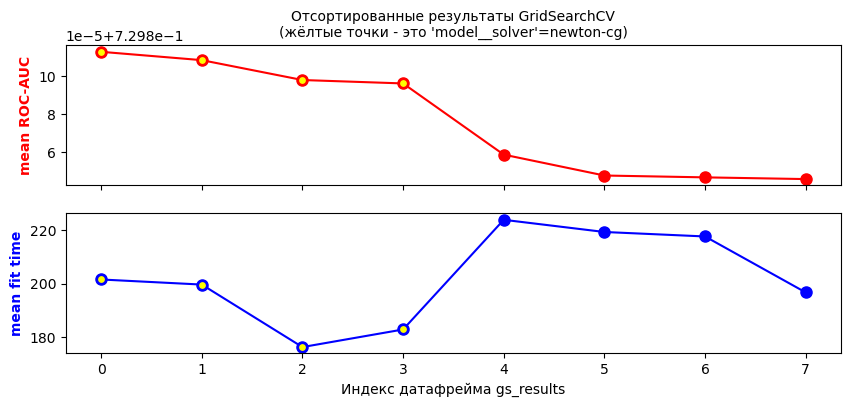

,model__C,model__class_weight,model__penalty,model__solver,rank_test_score,mean_test_score,mean_fit_time
0,30,balanced,l2,newton-cg,1,0.729913,201.555856
1,10,balanced,l2,newton-cg,2,0.729909,199.647614
2,100,balanced,l2,newton-cg,3,0.729898,176.222481
3,1,balanced,l2,newton-cg,4,0.729896,182.818027
4,100,balanced,l2,lbfgs,5,0.729859,223.922934
5,10,balanced,l2,lbfgs,6,0.729848,219.356540
6,1,balanced,l2,lbfgs,7,0.729847,217.681164
7,30,balanced,l2,lbfgs,8,0.729846,196.709606


In [20]:
lr_pipe_gs_results = visualize_gs_results(lr_pipe_gs, 'model__solver', 'newton-cg')
lr_pipe_gs_results

In [21]:
lr_pipe_best_params = lr_pipe_gs.best_params_
lr_pipe_best_params

{'model__C': 30,
 'model__class_weight': 'balanced',
 'model__penalty': 'l2',
 'model__solver': 'newton-cg'}

Наибольшее значение ROC-AUC получено при `C=30` и `solver='newton-cg'` — 0.729913. При этом разница между наибольшим и наименьшим значениями метрики среди всех восьми комбинаций составляет менее 0.0001. Оценим выбранную конфигурацию с помощью 3-кратной стратифицированной кросс-валидации.

In [22]:
# Чтобы можно было пропустить поиск по сетке

# lr_pipe_best_params = {
#     'model__C': 30,
#     'model__class_weight': 'balanced',
#     'model__penalty': 'l2',
#     'model__solver': 'newton-cg'
# }

In [23]:
lr_opt_pipe = lr_pipe
lr_opt_pipe.set_params(**lr_pipe_best_params)
lr_opt = lr_opt_pipe.named_steps['model']  # для раздела 5
del lr_pipe, lr

lr_opt_auc, _ = validate(
    lr_opt_pipe, X_train, y_train, skf, n_jobs=1,  pre_dispatch=1
);

Модель: Pipeline with LogisticRegression
[CV] END ................................ score: (test=0.733) total time= 2.6min
[CV] END ................................ score: (test=0.735) total time= 2.8min
[CV] END ................................ score: (test=0.734) total time= 2.6min
Продолжительность валидации: 8.0 мин
ROC-AUC mean: 0.7342
ROC-AUC std:  0.0009


После подбора гиперпараметров средний ROC-AUC логистической регрессии на 3-кратной стратифицированной кросс-валидации вырос с 0.7299 до 0.7342. На сформированном наборе признаков обе оценки ниже уровня 0.75, требуемого по условию задания на тестовом датасете.

In [24]:
lr_opt_auc  # для 3.7

0.7341786445781381

## 3.4 Случайный лес

Случайный лес не требует стандартизации признаков, поэтому будем использовать подготовленные данные без дополнительного масштабирования. Сначала оценим модель без подбора гиперпараметров с помощью 3-кратной стратифицированной кросс-валидации.

In [25]:
rf = RandomForestClassifier(n_jobs=-1, random_state=42)

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

In [26]:
validate(rf, X_train, y_train, skf, n_jobs=1,  pre_dispatch=1);

Модель: RandomForestClassifier
[CV] END ................................ score: (test=0.699) total time= 2.5min
[CV] END ................................ score: (test=0.702) total time= 2.5min
[CV] END ................................ score: (test=0.703) total time= 2.5min
Продолжительность валидации: 7.6 мин
ROC-AUC mean: 0.7011
ROC-AUC std:  0.0015


В предварительных экспериментах при `max_features=0.1` значение ROC-AUC составило 0.7449 против 0.7440 при `max_features='sqrt'`, однако время обучения было примерно вдвое больше. Поскольку значение `0.1` находилось на верхней границе исследованного диапазона, дополнительно проверили `max_features=0.15`. При этой настройке ROC-AUC составил около 0.744, а обучение заняло ещё больше времени.

Учитывая близкие значения ROC-AUC и существенную разницу во времени обучения, в итоговой сетке ограничимся значениями `max_features='sqrt'` и `'log2'`. Длительные расчёты с `max_features=0.1` и `0.15` повторять не будем.

In [27]:
%%time

param_grid = [
    # Минимальный размер листа
    {
        'n_estimators': [400],
        'max_depth': [None],
        'min_samples_leaf': [1, 20, 50],
        'max_features': ['sqrt'],
        'class_weight': [None],
    },

    # Ограничение глубины
    {
        'n_estimators': [400],
        'max_depth': [30],
        'min_samples_leaf': [20],
        'max_features': ['sqrt'],
        'class_weight': [None],
    },

    # Число деревьев
    {
        'n_estimators': [100, 600],
        'max_depth': [None],
        'min_samples_leaf': [20],
        'max_features': ['sqrt'],
        'class_weight': [None],
    },

    # Число признаков при разбиении
    {
        'n_estimators': [400],
        'max_depth': [None],
        'min_samples_leaf': [20],
        'max_features': ['log2'],
        'class_weight': [None],
    },

    # Учёт дисбаланса классов
    {
        'n_estimators': [400],
        'max_depth': [None],
        'min_samples_leaf': [20],
        'max_features': ['sqrt'],
        'class_weight': ['balanced', 'balanced_subsample'],
    },
]

strat_split_1 = StratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=42)

rf_gs = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=strat_split_1,
    n_jobs=1,
    pre_dispatch=1,
    verbose=3,
    refit=False,
)

rf_gs.fit(X_train, y_train);

Fitting 1 folds for each of 9 candidates, totalling 9 fits
[CV 1/1] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=1, n_estimators=400;, score=0.720 total time=13.6min
[CV 1/1] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=20, n_estimators=400;, score=0.744 total time=11.4min
[CV 1/1] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=50, n_estimators=400;, score=0.742 total time=10.6min
[CV 1/1] END class_weight=None, max_depth=30, max_features=sqrt, min_samples_leaf=20, n_estimators=400;, score=0.744 total time=11.0min
[CV 1/1] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=20, n_estimators=100;, score=0.739 total time= 3.0min
[CV 1/1] END class_weight=None, max_depth=None, max_features=sqrt, min_samples_leaf=20, n_estimators=600;, score=0.744 total time=17.5min
[CV 1/1] END class_weight=None, max_depth=None, max_features=log2, min_samples_leaf=20, n_estimators=400;, score=0.7

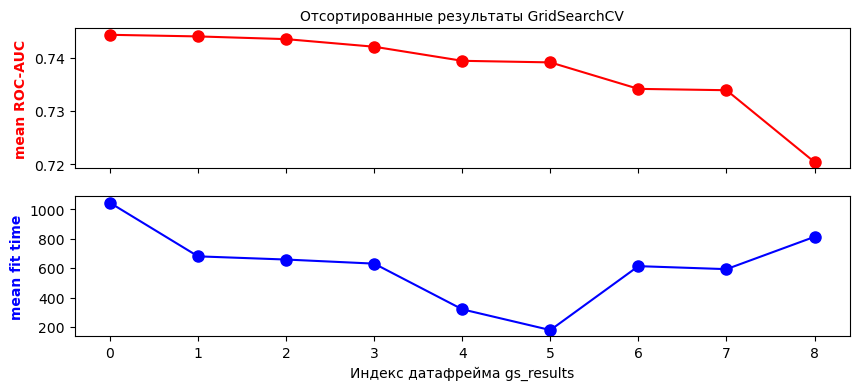

,class_weight,max_depth,max_features,min_samples_leaf,n_estimators,rank_test_score,mean_test_score,mean_fit_time
0,None,NaN,sqrt,20,600,1,0.744316,1042.939203
1,None,NaN,sqrt,20,400,2,0.744013,679.559009
2,None,30.0,sqrt,20,400,3,0.743504,657.910546
3,None,NaN,sqrt,50,400,4,0.742078,630.138579
4,None,NaN,log2,20,400,5,0.739436,320.114340
5,None,NaN,sqrt,20,100,6,0.739141,179.250642
6,balanced_subsample,NaN,sqrt,20,400,7,0.734170,613.105085
7,balanced,NaN,sqrt,20,400,8,0.733918,592.719534
8,None,NaN,sqrt,1,400,9,0.720434,812.171656


In [28]:
rf_gs_results = visualize_gs_results(rf_gs)
rf_gs_results

In [29]:
rf_gs.best_params_

{'class_weight': None,
 'max_depth': None,
 'max_features': 'sqrt',
 'min_samples_leaf': 20,
 'n_estimators': 600}

В текущей сетке наибольшее значение ROC-AUC получено при 600 деревьях — 0.7443. У конфигурации с 400 деревьями ROC-AUC составляет 0.7440, а обучение заняло около 11.3 мин против 17.4 мин при 600 деревьях. При столь близких оценках качества для дальнейшей работы выберем более быстрый вариант с 400 деревьями, сохранив остальные параметры лучшей комбинации. Оценим выбранную конфигурацию с помощью 3-кратной стратифицированной кросс-валидации.

In [30]:
rf_best_params = {
    'class_weight': None,
    'max_depth': None,
    'max_features': 'sqrt',
    'min_samples_leaf': 20,
    'n_estimators': 400
}

rf_opt = rf
rf_opt.set_params(**rf_best_params)
del rf

rf_opt_auc, _ = validate(
    rf_opt, X_train, y_train, skf, n_jobs=1, pre_dispatch=1
);

Модель: RandomForestClassifier
[CV] END ................................ score: (test=0.745) total time= 8.2min
[CV] END ................................ score: (test=0.749) total time= 8.3min
[CV] END ................................ score: (test=0.747) total time= 8.2min
Продолжительность валидации: 24.8 мин
ROC-AUC mean: 0.7469
ROC-AUC std:  0.0015


После подбора гиперпараметров средний ROC-AUC случайного леса на 3-кратной стратифицированной кросс-валидации вырос с 0.7011 до 0.7469. Полученная оценка выбранной конфигурации на 0.0031 ниже уровня 0.75, требуемого по условию задания на тестовом датасете.

In [31]:
rf_opt_auc  # для 3.7

0.7469011178358037

## 3.5 Линейный метод опорных векторов

In [32]:
svc = LinearSVC(dual=False, random_state=42)

svc_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', svc)
])

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

В этой работе предварительные оценки моделей были выполнены на данных, подготовленных с использованием параметра `drop='first'` в `OneHotEncoder` для небольшого сокращения числа признаков. На таких данных проведена предварительная настройка `LinearSVC`.

При `class_weight=None` проверены значения `C=0.001`, `0.01`, `0.1`, `1`, `10` и `100`; полученные значения ROC-AUC различались не более чем на 0.000111. При `C=0.01` использование `class_weight='balanced'` увеличило ROC-AUC на одном разбиении с 0.729293 до 0.729500. Отдельные расчёты занимали от 14 до 35 минут. В итоге расчётного времени потрачено много, а улучшение оказалось пренебрежимо малым: выбранная конфигурация (`C=0.01`, `class_weight='balanced'`) при трёхкратной кросс-валидации дала ROC-AUC 0.7335 ± 0.0009 против 0.7332 ± 0.0009 у исходной модели.

Сейчас данные подготовлены без удаления первой категории (`drop=None`). Это упрощает подсчёт количества уникальных значений категориальных признаков в подразделе 4.5, а качество моделей при этом не ухудшилось. Пересчитаем значение метрики исходной модели (без настройки) после этого небольшого изменения подготовки данных.

In [33]:
validate(
    svc_pipe, X_train, y_train, skf, n_jobs=1, pre_dispatch=1
);

Модель: Pipeline with LinearSVC
[CV] END ................................ score: (test=0.732) total time= 6.2min
[CV] END ................................ score: (test=0.734) total time= 6.9min
[CV] END ................................ score: (test=0.733) total time= 6.8min
Продолжительность валидации: 19.9 мин
ROC-AUC mean: 0.7332
ROC-AUC std:  0.0009


Во всех трёх фолдах значения метрики при округлении до трёх знаков получились такими же, а среднее значение при округлении до четырёх знаков полностью совпало со значением при `drop='first'`. При этом время расчёта сократилось с 62.2 до 19.9 мин. Это любопытно. При `dual=False` решается прямая задача, и скорость сильно зависит от геометрии и масштабирования данных.

Пересчёт всей сетки потребует много времени, хотя, похоже, что в разы меньше первого раза, и есть основания полагать, что результаты будут почти такие же, а может и полностью совпадающие. Поэтому с `drop=None` проверим только лучшую конфигурацию по предварительной настройке с `drop='first'`.

In [34]:
# Лучшие параметры предварительной настройки с drop='first'

svc_pipe_best_params = {
    'model__C': 0.01,
    'model__class_weight': 'balanced'
}

In [35]:
svc_opt_pipe = svc_pipe
svc_opt_pipe.set_params(**svc_pipe_best_params)
del svc_pipe

validate(
    svc_opt_pipe, X_train, y_train, skf, n_jobs=1, pre_dispatch=1
);

Модель: Pipeline with LinearSVC
[CV] END ................................ score: (test=0.732) total time=11.1min
[CV] END ................................ score: (test=0.735) total time= 9.1min
[CV] END ................................ score: (test=0.733) total time= 8.1min
Продолжительность валидации: 28.3 мин
ROC-AUC mean: 0.7335
ROC-AUC std:  0.0010


При переходе от `drop='first'` к `drop=None` продолжительность валидации выбранной конфигурации сократилась со 110.4 до 28.3 мин. Результат практически не изменился: 0.7335 ± 0.0010 против 0.7335 ± 0.0009.

На 3-кратной стратифицированной кросс-валидации средний ROC-AUC составил 0.7332 у исходной модели и 0.7335 у настроенной. Разница — всего 0.0003 при СКО около 0.001. До требуемого на тестовом датасете уровня 0.75 не хватает 0.0165 — примерно в 55 раз больше этой разницы. Поэтому исключаем `LinearSVC` из дальнейшего сравнения.

## 3.6 Многослойный перцептрон

### 3.6.1 MLPClassifier из scikit-learn

In [36]:
mlp = MLPClassifier(random_state=42)

mlp_pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', mlp),
])

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

In [37]:
validate(
    mlp_pipe, X_train, y_train, skf, n_jobs=1, pre_dispatch=1
);

Модель: Pipeline with MLPClassifier
[CV] END ................................ score: (test=0.717) total time= 7.8min
[CV] END ................................ score: (test=0.716) total time=10.8min
[CV] END ................................ score: (test=0.717) total time=10.3min
Продолжительность валидации: 28.9 мин
ROC-AUC mean: 0.7163
ROC-AUC std:  0.0006


У исходной модели средний ROC-AUC составил 0.7163, а 3-кратная валидация заняла 28.9 мин. Попробуем раннюю остановку обучения (`early_stopping=True`). В этом режиме модель выделяет часть обучающих данных для внутренней валидации и прекращает обучение, когда accuracy на ней перестаёт улучшаться в течение нескольких эпох.

In [38]:
mlp_pipe.set_params(model__early_stopping=True);

In [39]:
validate(
    mlp_pipe, X_train, y_train, skf, n_jobs=1, pre_dispatch=1
);

Модель: Pipeline with MLPClassifier
[CV] END ................................ score: (test=0.745) total time= 1.1min
[CV] END ................................ score: (test=0.749) total time= 1.1min
[CV] END ................................ score: (test=0.739) total time= 1.1min
Продолжительность валидации: 3.2 мин
ROC-AUC mean: 0.7446
ROC-AUC std:  0.0040


С ранней остановкой средний ROC-AUC на 3-кратной стратифицированной кросс-валидации составил 0.7446 против 0.7163 без неё, а продолжительность валидации — 3.2 мин против 28.9 мин. При этом ранняя остановка в `MLPClassifier` ориентируется на accuracy, а не на ROC-AUC. Сохраним `early_stopping=True` и перейдём к подбору других гиперпараметров.

In [40]:
%%time

param_grid = [
    {
        'model__hidden_layer_sizes': [
            (64, 32),
            (128, 64),
            (256, 64),
            (256, 128),
        ],
        'model__learning_rate_init': [
            0.0003,
            0.001,
            0.003,
        ],
        'model__batch_size': [200],
        'model__alpha': [1e-4],
    },
    {
        'model__hidden_layer_sizes': [(128, 64)],
        'model__learning_rate_init': [0.001],
        'model__batch_size': [
            512,
            1024,
            2048,
            4096,
        ],
        'model__alpha': [1e-4],
    },
    {
        'model__hidden_layer_sizes': [(128, 64)],
        'model__learning_rate_init': [0.001],
        'model__batch_size': [200],
        'model__alpha': [
            0,
            1e-3,
        ],
    },
]

strat_split_1 = StratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=42)

mlp_pipe_gs = GridSearchCV(
    estimator=mlp_pipe,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=strat_split_1,
    n_jobs=1,
    pre_dispatch=1,
    verbose=3,
    refit=False,
)

mlp_pipe_gs.fit(X_train, y_train);

Fitting 1 folds for each of 18 candidates, totalling 18 fits
[CV 1/1] END model__alpha=0.0001, model__batch_size=200, model__hidden_layer_sizes=(64, 32), model__learning_rate_init=0.0003;, score=0.732 total time= 1.4min
[CV 1/1] END model__alpha=0.0001, model__batch_size=200, model__hidden_layer_sizes=(64, 32), model__learning_rate_init=0.001;, score=0.745 total time= 1.4min
[CV 1/1] END model__alpha=0.0001, model__batch_size=200, model__hidden_layer_sizes=(64, 32), model__learning_rate_init=0.003;, score=0.748 total time= 1.4min
[CV 1/1] END model__alpha=0.0001, model__batch_size=200, model__hidden_layer_sizes=(128, 64), model__learning_rate_init=0.0003;, score=0.742 total time= 1.8min
[CV 1/1] END model__alpha=0.0001, model__batch_size=200, model__hidden_layer_sizes=(128, 64), model__learning_rate_init=0.001;, score=0.749 total time= 1.8min
[CV 1/1] END model__alpha=0.0001, model__batch_size=200, model__hidden_layer_sizes=(128, 64), model__learning_rate_init=0.003;, score=0.748 total

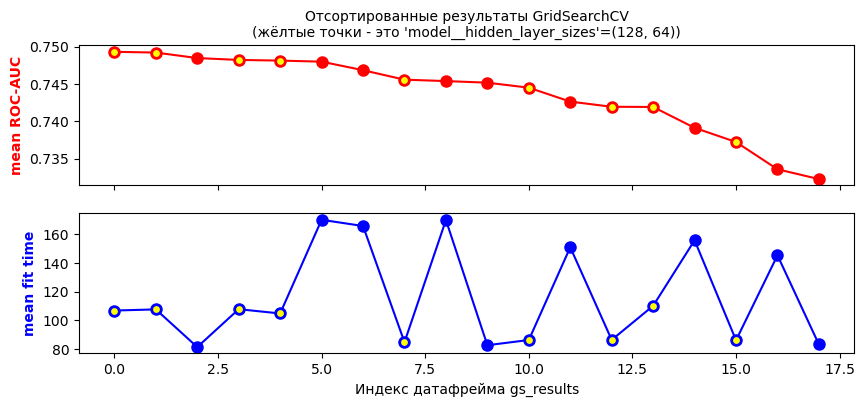

,model__alpha,model__batch_size,model__hidden_layer_sizes,model__learning_rate_init,rank_test_score,mean_test_score,mean_fit_time
0,0.0000,200,"(128, 64)",0.0010,1,0.749321,106.888999
1,0.0001,200,"(128, 64)",0.0010,2,0.749218,107.684001
2,0.0001,200,"(64, 32)",0.0030,3,0.748482,81.487000
3,0.0010,200,"(128, 64)",0.0010,4,0.748230,107.835999
4,0.0001,200,"(128, 64)",0.0030,5,0.748140,104.850999
5,0.0001,200,"(256, 128)",0.0030,6,0.747998,169.973017
6,0.0001,200,"(256, 128)",0.0010,7,0.746852,165.663994
7,0.0001,1024,"(128, 64)",0.0010,8,0.745582,84.883000
8,0.0001,200,"(256, 128)",0.0003,9,0.745391,169.810000
9,0.0001,200,"(64, 32)",0.0010,10,0.745178,82.775000


In [41]:
mlp_pipe_gs_results = visualize_gs_results(mlp_pipe_gs, 'model__hidden_layer_sizes', (128, 64))
mlp_pipe_gs_results

In [42]:
mlp_pipe_best_params = mlp_pipe_gs.best_params_
mlp_pipe_best_params

{'model__alpha': 0,
 'model__batch_size': 200,
 'model__hidden_layer_sizes': (128, 64),
 'model__learning_rate_init': 0.001}

В текущей сетке наибольший ROC-AUC на одном стратифицированном разбиении составил 0.7493. Оценим выбранную конфигурацию с помощью 3-кратной стратифицированной кросс-валидации.

In [43]:
# Чтобы можно было пропустить поиск по сетке

# mlp_pipe_best_params = {
#     'model__alpha': 0,
#     'model__batch_size': 200,
#     'model__hidden_layer_sizes': (128, 64),
#     'model__learning_rate_init': 0.001
# }

In [44]:
mlp_opt_pipe = mlp_pipe
mlp_opt_pipe.set_params(**mlp_pipe_best_params)
mlp_opt = mlp_opt_pipe.named_steps['model']  # для раздела 5
del mlp_pipe, mlp

mlp_opt_auc, _ = validate(
    mlp_opt_pipe, X_train, y_train, skf, n_jobs=1, pre_dispatch=1
)

Модель: Pipeline with MLPClassifier
[CV] END ................................ score: (test=0.752) total time= 1.3min
[CV] END ................................ score: (test=0.744) total time= 1.3min
[CV] END ................................ score: (test=0.748) total time= 1.3min
Продолжительность валидации: 4.0 мин
ROC-AUC mean: 0.7478
ROC-AUC std:  0.0032


Среди рассмотренных моделей многослойный перцептрон пока ближе всего к уровню ROC-AUC 0.75, требуемому на тестовом датасете. Его средний ROC-AUC — 0.7478, то есть ниже требуемого уровня на 0.0022. Эта разность меньше СКО оценок по фолдам, которое составило 0.0032.

In [45]:
mlp_opt_auc  # для 3.7

0.747753306677937

### 3.6.2 Собственная реализация MLP на PyTorch

In [46]:
print(torch.__version__)
print(torch.version.cuda)

2.12.1+cu126
12.6


Реализуем многослойный перцептрон на PyTorch с возможностью обучения на GPU. Собственная реализация позволит отслеживать ROC-AUC на внутренней валидационной выборке после каждой эпохи для ранней остановки. Обеспечим совместимость с библиотекой scikit-learn.

In [47]:
class CreditRiskMLP(nn.Module):
    def __init__(
        self,
        input_size,
        hidden_layer_sizes=(128, 64),
        use_batch_norm=False,
        activation='relu',
    ):
        super().__init__()

        activation_layers = {
            'relu': nn.ReLU,
            'leaky_relu': nn.LeakyReLU,
            'tanh': nn.Tanh,
        }

        if activation not in activation_layers:
            raise ValueError(f'Unknown activation: {activation}')

        activation_layer = activation_layers[activation]

        layers = []
        previous_size = input_size

        for hidden_size in hidden_layer_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))

            if use_batch_norm:
                layers.append(nn.BatchNorm1d(hidden_size))

            layers.append(activation_layer())
            previous_size = hidden_size

        layers.append(nn.Linear(previous_size, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)

In [48]:
class TorchMLPClassifier(ClassifierMixin, BaseEstimator):
    def __init__(
        self,
        hidden_layer_sizes=(128, 64),
        batch_size=4096,
        max_epochs=10,
        learning_rate=0.001,
        weight_decay=0.0,
        use_pos_weight=False,
        early_stopping=False,
        use_batch_norm=False,
        validation_fraction=0.1,
        patience=2,
        random_state=42,
        device='cpu',
        verbose=True,
        activation='relu',
    ):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.learning_rate = learning_rate
        self.weight_decay = weight_decay
        self.use_pos_weight = use_pos_weight
        self.early_stopping = early_stopping
        self.use_batch_norm = use_batch_norm
        self.validation_fraction = validation_fraction
        self.patience = patience
        self.random_state = random_state
        self.device = device
        self.verbose = verbose
        self.activation = activation


    def fit(self, X, y):
        self.classes_ = np.array([0, 1])  # для нормальной sklearn-совместимости
        X, y = np.asarray(X), np.asarray(y)

        X_train, X_val, y_train, y_val = train_test_split(
            X, y,
            test_size=self.validation_fraction,
            random_state=self.random_state,
            stratify=y,
        )

        X_train_tensor = torch.from_numpy(X_train).float()
        y_train_tensor = torch.from_numpy(y_train).float()
        train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

        X_val_tensor = torch.from_numpy(X_val).float()
        y_val_tensor = torch.from_numpy(y_val).float()
        val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

        train_generator = torch.Generator()
        train_generator.manual_seed(self.random_state)
        pin_memory = self.device == 'cuda'

        train_loader = DataLoader(
            train_dataset,
            batch_size=self.batch_size,
            shuffle=True,
            pin_memory=pin_memory,
            generator=train_generator
        )
        val_loader = DataLoader(
            val_dataset,
            batch_size=self.batch_size,
            shuffle=False,
            pin_memory=pin_memory,
        )

        torch.manual_seed(self.random_state)

        self.model_ = CreditRiskMLP(
            input_size=X.shape[1],
            hidden_layer_sizes=self.hidden_layer_sizes,
            use_batch_norm=self.use_batch_norm,
            activation=self.activation,
        ).to(self.device)

        if self.use_pos_weight:
            n_positive = y_train_tensor.sum().item()
            n_negative = len(y_train_tensor) - n_positive

            pos_weight = torch.tensor(
                n_negative / n_positive,
                dtype=torch.float32,
                device=self.device
            )
        else:
            pos_weight = None

        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

        optimizer = torch.optim.Adam(
            self.model_.parameters(),
            lr=self.learning_rate,
            weight_decay=self.weight_decay
        )

        epoch_iterator = (
            tqdm(range(self.max_epochs), desc='Training', unit='epoch', ncols=100)
            if self.verbose
            else range(self.max_epochs)
        )

        self.val_auc_history_ = []
        if self.early_stopping:
            best_auc = -np.inf
            best_state = None
            epochs_without_improvement = 0

        for epoch in epoch_iterator:
            self.model_.train()
            for X_batch, y_batch in train_loader:
                X_batch = X_batch.to(self.device, non_blocking=pin_memory)
                y_batch = y_batch.to(self.device, non_blocking=pin_memory)
                optimizer.zero_grad()
                pred_batch = self.model_(X_batch)
                loss_batch = criterion(pred_batch, y_batch)
                loss_batch.backward()
                optimizer.step()

            val_auc = self._calc_auc(val_loader)
            self.val_auc_history_.append(val_auc)

            if self.early_stopping:
                if val_auc > best_auc:
                    best_auc = val_auc
                    best_state = copy.deepcopy(self.model_.state_dict())
                    epochs_without_improvement = 0
                else:
                    epochs_without_improvement += 1

                if epochs_without_improvement >= self.patience:
                    break

        if self.early_stopping:
            self.model_.load_state_dict(best_state)
        return self


    def _calc_auc(self, val_loader):
        self.model_.eval()
        y_true, y_pred = [], []
        pin_memory = self.device == 'cuda'

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(self.device, non_blocking=pin_memory)
                pred_batch = self.model_(X_batch)

                y_true.append(y_batch.numpy())
                y_pred.append(pred_batch.cpu().numpy())

        return roc_auc_score(
            np.concatenate(y_true),
            np.concatenate(y_pred)
        )


    def predict_proba(self, X):
        check_is_fitted(self, 'model_')
        self.model_.eval()
        X_tensor = torch.from_numpy(np.asarray(X, dtype=np.float32))
        pin_memory = self.device == 'cuda'
        loader = DataLoader(
            TensorDataset(X_tensor),
            batch_size=self.batch_size,
            shuffle=False,
            pin_memory=pin_memory
        )
        proba = []
        with torch.no_grad():
            for (X_batch,) in loader:
                X_batch = X_batch.to(self.device, non_blocking=pin_memory)
                logits_batch = self.model_(X_batch)
                proba_batch = torch.sigmoid(logits_batch)
                proba.append(proba_batch.cpu().numpy())

        proba = np.concatenate(proba)
        return np.column_stack((1 - proba, proba))


    def predict(self, X):
        proba = self.predict_proba(X)[:, 1]
        return (proba >= 0.5).astype(int)

In [49]:
# Для использования GPU

device = 'cuda' if torch.cuda.is_available() else 'cpu'
# device = 'cpu'  # насильно выбрать CPU для сравнения скорости
print(f'device: {device}')

device: cuda


Начнём с `hidden_layer_sizes=(128, 64)` — лучшего варианта при настройке `MLPClassifier`.

In [50]:
%%time

torch_mlp = TorchMLPClassifier(
    hidden_layer_sizes=(128, 64),
    device=device,
    random_state=42,
)

torch_mlp_pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', torch_mlp),
])

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

cv_results = cross_validate(
    torch_mlp_pipe, X_train, y_train, cv=skf,
    scoring='roc_auc',
    return_estimator=True,
    n_jobs=1,
    pre_dispatch=1,
    verbose=3,
)
print(f'ROC-AUC mean: {cv_results['test_score'].mean():.4f}')
print(f'ROC-AUC std:  {cv_results['test_score'].std():.4f}\n')

val_auc_histories = [
    estimator.named_steps['model'].val_auc_history_
    for estimator in cv_results['estimator']
]
mean_auc_by_epoch = np.mean(val_auc_histories, axis=0)
std_auc_by_epoch = np.std(val_auc_histories, axis=0)

Training: 100%|██████████████████████████████████████████████████| 10/10 [01:58<00:00, 11.84s/epoch]


[CV] END ......................................., score=0.748 total time= 2.3min


Training: 100%|██████████████████████████████████████████████████| 10/10 [01:58<00:00, 11.81s/epoch]


[CV] END ......................................., score=0.747 total time= 2.3min


Training: 100%|██████████████████████████████████████████████████| 10/10 [01:57<00:00, 11.77s/epoch]


[CV] END ......................................., score=0.739 total time= 2.3min
ROC-AUC mean: 0.7449
ROC-AUC std:  0.0040

CPU times: total: 36min 56s
Wall time: 6min 50s


Использование GPU сократило время валидации лишь примерно на 10 %. Вероятно, при сравнительно небольшой нейронной сети значительную часть времени занимают подготовка данных и другие операции на CPU, которые не ускоряет перенос вычислений нейросети на GPU. Дополнительного времени требует и обмен данными между CPU и GPU.

С учётом дисбаланса классов попробуем `use_pos_weight=True`.

In [51]:
%%time

torch_mlp_pipe.set_params(model__use_pos_weight=True)

cv_results = cross_validate(
    torch_mlp_pipe, X_train, y_train, cv=skf,
    scoring='roc_auc',
    return_estimator=True,
    n_jobs=1,
    pre_dispatch=1,
    verbose=3,
)
print(f'ROC-AUC mean: {cv_results['test_score'].mean():.4f}')
print(f'ROC-AUC std:  {cv_results['test_score'].std():.4f}\n')

val_auc_histories = [
    estimator.named_steps['model'].val_auc_history_
    for estimator in cv_results['estimator']
]
mean_auc_by_epoch_pos_weight = np.mean(val_auc_histories, axis=0)
std_auc_by_epoch_pos_weight = np.std(val_auc_histories, axis=0)

Training: 100%|██████████████████████████████████████████████████| 10/10 [01:57<00:00, 11.80s/epoch]


[CV] END ......................................., score=0.748 total time= 2.3min


Training: 100%|██████████████████████████████████████████████████| 10/10 [01:58<00:00, 11.82s/epoch]


[CV] END ......................................., score=0.746 total time= 2.3min


Training: 100%|██████████████████████████████████████████████████| 10/10 [01:58<00:00, 11.83s/epoch]


[CV] END ......................................., score=0.740 total time= 2.3min
ROC-AUC mean: 0.7448
ROC-AUC std:  0.0034

CPU times: total: 36min 56s
Wall time: 6min 48s


После 10 эпох средний ROC-AUC на кросс-валидации почти одинаков: 0.7449 без взвешивания классов и 0.7448 с ним. Посмотрим, как по эпохам менялся средний ROC-AUC на внутренних валидационных выборках.

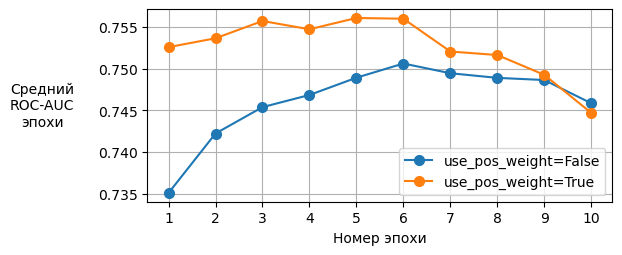

Максимальное значение ROC-AUC: 0.7561


In [52]:
n = len(mean_auc_by_epoch)
plt.figure(figsize=(6, 2.5))
plt.grid()
plt.plot(
    range(1, n + 1), mean_auc_by_epoch,
    '-o', ms=7, label='use_pos_weight=False'
)
plt.plot(
    range(1, n + 1), mean_auc_by_epoch_pos_weight,
    '-o', ms=7, label='use_pos_weight=True'
)
plt.xticks(range(1, n + 1))
plt.xlabel('Номер эпохи')
plt.ylabel(
    'Средний\nROC-AUC\nэпохи',
    ha='center', va='center', rotation=0, labelpad=40
)
plt.legend()
plt.show()
max_auc = max(max(mean_auc_by_epoch), max(mean_auc_by_epoch_pos_weight))
print(f'Максимальное значение ROC-AUC: {max_auc:.4f}')

Со взвешиванием классов максимум среднего ROC-AUC на внутренних валидационных выборках выше, оставляем `use_pos_weight=True`. К 10-й эпохе ROC-AUC снижается в обоих случаях. Оптимальное число эпох зависит от конфигурации. Чтобы не выбирать его вручную при дальнейшем подборе гиперпараметров, включим раннюю остановку с восстановлением весов лучшей эпохи. После кратковременного снижения ROC-AUC может снова вырасти. Поэтому зададим `patience=3`: ранняя остановка сработает после трёх эпох подряд без нового максимума ROC-AUC на внутренней валидационной выборке.

In [53]:
torch_mlp_pipe.set_params(
    model__early_stopping=True,
    model__patience=3,
)

validate(
    torch_mlp_pipe, X_train, y_train, skf, n_jobs=1, pre_dispatch=1,
);

Модель: Pipeline with TorchMLPClassifier


Training:  80%|████████████████████████████████████████▊          | 8/10 [01:47<00:26, 13.40s/epoch]


[CV] END ................................ score: (test=0.755) total time= 2.1min


Training:  50%|█████████████████████████▌                         | 5/10 [01:10<01:10, 14.18s/epoch]


[CV] END ................................ score: (test=0.757) total time= 1.5min


Training:  60%|██████████████████████████████▌                    | 6/10 [01:22<00:55, 13.83s/epoch]


[CV] END ................................ score: (test=0.757) total time= 1.7min
Продолжительность валидации: 5.2 мин
ROC-AUC mean: 0.7561
ROC-AUC std:  0.0009


С ранней остановкой средний ROC-AUC на кросс-валидации вырос с 0.7448 до 0.7561 и впервые превысил уровень 0.75. Продолжительность валидации сократилась с 6.8 до 5.2 мин.

Для сравнения персептронов до настройки отдельно проверили `(100,)` — как у `MLPClassifier` по умолчанию. При `early_stopping=True` без взвешивания классов средний ROC-AUC на 3-кратной стратифицированной кросс-валидации составил 0.7454.

Теперь попробуем `use_batch_norm=True`. Этот параметр добавляет пакетную нормализацию (Batch Normalization) перед функциями активации скрытых слоёв.

In [54]:
torch_mlp_pipe.set_params(model__use_batch_norm=True)

validate(
    torch_mlp_pipe, X_train, y_train, skf, n_jobs=1, pre_dispatch=1,
);

Модель: Pipeline with TorchMLPClassifier


Training:  80%|████████████████████████████████████████▊          | 8/10 [01:48<00:27, 13.52s/epoch]


[CV] END ................................ score: (test=0.751) total time= 2.1min


Training:  60%|██████████████████████████████▌                    | 6/10 [01:23<00:55, 13.95s/epoch]


[CV] END ................................ score: (test=0.755) total time= 1.7min


Training:  60%|██████████████████████████████▌                    | 6/10 [01:24<00:56, 14.05s/epoch]


[CV] END ................................ score: (test=0.756) total time= 1.7min
Продолжительность валидации: 5.5 мин
ROC-AUC mean: 0.7539
ROC-AUC std:  0.0019


При включении пакетной нормализации средний ROC-AUC на кросс-валидации снизился с 0.7561 до 0.7539. По результатам проверки не ожидаем преимущества от пакетной нормализации, поэтому дальнейший подбор гиперпараметров проведём при `use_batch_norm=False`.

In [55]:
%%time

torch_mlp_pipe.set_params(
    model__use_batch_norm=False,
    model__max_epochs=15,  # чтобы точно хватало для early_stopping
)

param_grid = [
    {
        'model__hidden_layer_sizes': [
            (64, 32),
            (128, 64),
            (256, 64),
            (256, 128),
            (512, 256),
        ],
        'model__learning_rate': [
            0.001,
            0.002,
            0.003,
        ],
        'model__batch_size': [4096],
        'model__weight_decay': [1e-4],
    },
    {
        'model__hidden_layer_sizes': [(256, 128)],
        'model__learning_rate': [0.002],
        'model__batch_size': [
            2048,
            8192,
        ],
        'model__weight_decay': [1e-4],
    },
    {
        'model__hidden_layer_sizes': [(256, 128)],
        'model__learning_rate': [0.002],
        'model__batch_size': [4096],
        'model__weight_decay': [0],
    },
]

strat_split_1 = StratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=42)

torch_mlp_pipe_gs = GridSearchCV(
    estimator=torch_mlp_pipe,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=strat_split_1,
    n_jobs=1,
    pre_dispatch=1,
    verbose=3,
    refit=False,
)

torch_mlp_pipe_gs.fit(X_train, y_train);

Fitting 1 folds for each of 18 candidates, totalling 18 fits


Training:  40%|████████████████████▍                              | 6/15 [01:53<02:50, 18.92s/epoch]


[CV 1/1] END model__batch_size=4096, model__hidden_layer_sizes=(64, 32), model__learning_rate=0.001, model__weight_decay=0.0001;, score=0.751 total time= 2.2min


Training:  33%|█████████████████                                  | 5/15 [01:36<03:13, 19.36s/epoch]


[CV 1/1] END model__batch_size=4096, model__hidden_layer_sizes=(64, 32), model__learning_rate=0.002, model__weight_decay=0.0001;, score=0.750 total time= 2.0min


...

[CV 1/1] END model__batch_size=2048, model__hidden_layer_sizes=(256, 128), model__learning_rate=0.002, model__weight_decay=0.0001;, score=0.752 total time= 2.6min


Training:  47%|███████████████████████▊                           | 7/15 [02:27<02:48, 21.08s/epoch]


[CV 1/1] END model__batch_size=8192, model__hidden_layer_sizes=(256, 128), model__learning_rate=0.002, model__weight_decay=0.0001;, score=0.752 total time= 2.8min


Training:  33%|█████████████████                                  | 5/15 [01:36<03:13, 19.37s/epoch]


[CV 1/1] END model__batch_size=4096, model__hidden_layer_sizes=(256, 128), model__learning_rate=0.002, model__weight_decay=0;, score=0.751 total time= 2.0min
CPU times: total: 3h 40min 22s
Wall time: 41min 57s


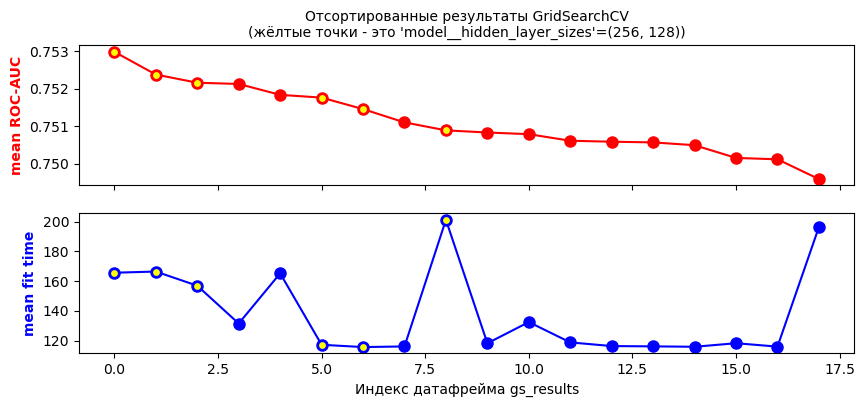

,model__batch_size,model__hidden_layer_sizes,model__learning_rate,model__weight_decay,rank_test_score,mean_test_score,mean_fit_time
0,4096,"(256, 128)",0.002,0.0001,1,0.752984,165.627001
1,8192,"(256, 128)",0.002,0.0001,2,0.752378,166.422997
2,2048,"(256, 128)",0.002,0.0001,3,0.752159,156.902000
3,4096,"(128, 64)",0.001,0.0001,4,0.752127,131.520999
4,4096,"(512, 256)",0.003,0.0001,5,0.751836,165.201000
5,4096,"(256, 128)",0.001,0.0001,6,0.751763,117.242000
6,4096,"(256, 128)",0.002,0.0000,7,0.751456,115.689003
7,4096,"(256, 64)",0.001,0.0001,8,0.751101,116.120999
8,4096,"(256, 128)",0.003,0.0001,9,0.750889,201.166999
9,4096,"(256, 64)",0.002,0.0001,10,0.750832,118.241001


In [56]:
torch_mlp_pipe_gs_results = visualize_gs_results(
    torch_mlp_pipe_gs, 'model__hidden_layer_sizes', (256, 128)
)
torch_mlp_pipe_gs_results

In [57]:
torch_mlp_pipe_best_params = torch_mlp_pipe_gs.best_params_
torch_mlp_pipe_best_params

{'model__batch_size': 4096,
 'model__hidden_layer_sizes': (256, 128),
 'model__learning_rate': 0.002,
 'model__weight_decay': 0.0001}

Лучший результат на одном стратифицированном разбиении получен при `hidden_layer_sizes=(256, 128)`, `learning_rate=0.002`, `batch_size=4096` и `weight_decay=1e-4`. Изменение размера батча и отключение регуляризации при остальных одинаковых параметрах не улучшили результат. Проверим выбранную конфигурацию на 3-кратной стратифицированной кросс-валидации.

In [58]:
# Чтобы можно было пропустить поиск по сетке

# torch_mlp_pipe_best_params = {
#     'model__batch_size': 4096,
#     'model__hidden_layer_sizes': (256, 128),
#     'model__learning_rate': 0.002,
#     'model__weight_decay': 0.0001
# }

In [59]:
torch_mlp_opt_pipe = torch_mlp_pipe
torch_mlp_opt_pipe.set_params(**torch_mlp_pipe_best_params)
del torch_mlp_pipe

torch_mlp_opt_auc, _ = validate(
    torch_mlp_opt_pipe, X_train, y_train, skf, n_jobs=1, pre_dispatch=1
)
del X_train, y_train  # освобождаем память

Модель: Pipeline with TorchMLPClassifier


Training:  47%|███████████████████████▊                           | 7/15 [01:36<01:50, 13.82s/epoch]


[CV] END ................................ score: (test=0.755) total time= 1.9min


Training:  27%|█████████████▌                                     | 4/15 [00:59<02:42, 14.75s/epoch]


[CV] END ................................ score: (test=0.753) total time= 1.3min


Training:  40%|████████████████████▍                              | 6/15 [01:23<02:05, 13.92s/epoch]


[CV] END ................................ score: (test=0.755) total time= 1.7min
Продолжительность валидации: 4.9 мин
ROC-AUC mean: 0.7547
ROC-AUC std:  0.0009


Подбор гиперпараметров на одном стратифицированном разбиении не дал улучшения на 3-кратной стратифицированной кросс-валидации. Средний ROC-AUC составил 0.7547 против 0.7561 до подбора. Окончательный выбор гиперпараметров отложим до повторной настройки после формирования итогового набора признаков.

In [60]:
torch_mlp_opt_auc  # для 3.7

0.7546997817288886

## 3.7 Выбор модели для конструирования признаков

In [61]:
# lr_opt_auc = 0.7341786445781381
# rf_opt_auc = 0.7469011178358037
# mlp_opt_auc = 0.747753306677937
# torch_mlp_opt_auc = 0.7546997817288886

In [62]:
pd.DataFrame(
    {'ROC-AUC': np.round([
        lr_opt_auc, rf_opt_auc,
        mlp_opt_auc, torch_mlp_opt_auc
    ], 4)},
    index=pd.Index([
        'LogisticRegression',
        'RandomForestClassifier',
        'MLPClassifier',
        'TorchMLPClassifier',
    ], name='Model')
)

,ROC-AUC
Model,
LogisticRegression,0.7342
RandomForestClassifier,0.7469
MLPClassifier,0.7478
TorchMLPClassifier,0.7547


На 3-кратной стратифицированной кросс-валидации только `TorchMLPClassifier` показал средний ROC-AUC выше 0.75. Выберем его для дальнейших экспериментов. После конструирования признаков повторно сравним модели.

# 4 Конструирование признаков

## 4.1 Агрегация кредитной истории

В базовом варианте агрегации значения признаков суммируются по всей кредитной истории, то есть все кредитные продукты имеют одинаковый вес. Попробуем использовать веса, пропорциональные `rn`, чтобы более поздние продукты вносили больший вклад. Сравним несколько вариантов нормировки весов и проверим добавление `credit_count` — числа кредитных продуктов в истории. Взвешенные one-hot-признаки будем хранить в `float32` вместо `uint8`, поэтому они будут занимать больше памяти.

In [63]:
%%time

ohe = OneHotEncoder(
    categories=[sorted(categories[f]) for f in categorical_features],
    sparse_output=False,
    dtype='uint8',  # так займёт в разы меньше памяти, чем float64
)
prepared_parts_weighted = []

for i, path in tqdm(
    enumerate(file_paths), desc='Processing files', unit='file', total=len(file_paths)
):
    df = pd.read_parquet(path)

    # Категориальные признаки
    if i == 0:
        categorical_ohe = ohe.fit_transform(df[categorical_features])
    else:
        categorical_ohe = ohe.transform(df[categorical_features])

    categorical_ohe_df = pd.DataFrame(
        data=categorical_ohe,
        index=df['id'],
        columns=ohe.get_feature_names_out(),
    )

    # Теперь не просто складываем, а с весами
    rn_weights = (
        # pd.Series(1, index=df.index)  # все веса единицы, просто сумма
        # df['rn']  # без нормировки
        df['rn'] / df.groupby('id')['rn'].transform('sum')
        # df['rn'] / df.groupby('id')['rn'].transform('max')
        # df['rn'] / df.groupby('id')['rn'].transform('mean')
    ).to_numpy(dtype='float32')

    cat_ohe_weighted_sum = (
        categorical_ohe_df
        .mul(rn_weights, axis=0)
        .groupby(level=0)
        .sum()
    )

    # Бинарные признаки
    # Теперь не просто складываем, а с весами
    binary_weighted_sum = (
        df[binary_features]
        .astype('float32')
        .mul(rn_weights, axis=0)
        .groupby(df['id'])
        .sum()
    )

    # Количество кредитных продуктов в кредитной истории
    credit_count = df.groupby('id').size().rename('credit_count')

    # Объединяем все признаки
    df_prep_weighted = pd.concat(
        [
            credit_count,
            cat_ohe_weighted_sum,
            binary_weighted_sum
        ],
        axis=1
    )
    # Добавляем обработанную часть в список
    prepared_parts_weighted.append(df_prep_weighted)

prepared_data_weighted = pd.concat(prepared_parts_weighted)

del (  # освобождаем память
    df, categorical_ohe, categorical_ohe_df,
    rn_weights, cat_ohe_weighted_sum,
    binary_weighted_sum, credit_count,
    df_prep_weighted, prepared_parts_weighted
)

print('Размеры подготовленных данных:', prepared_data_weighted.shape)
print('Количество повторов индекса:', prepared_data_weighted.index.duplicated().sum())
print('Количество пропусков:', prepared_data_weighted.isna().sum().sum())
print('\nPrepared data info:')
prepared_data_weighted.info()
print()

Processing files: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [01:21<00:00,  6.78s/file]


Размеры подготовленных данных: (3000000, 410)
Количество повторов индекса: 0
Количество пропусков: 0

Prepared data info:
<class 'pandas.core.frame.DataFrame'>
Index: 3000000 entries, 0 to 2999999
Columns: 410 entries, credit_count to fclose_flag
dtypes: float32(409), int64(1)
memory usage: 4.7 GB

CPU times: total: 1min 43s
Wall time: 1min 23s


In [64]:
# Объединяем матрицу признаков с целевой переменной

flag = pd.read_csv('train_target.csv', index_col='id')
prepared_dataset_weighted = pd.concat([prepared_data_weighted, flag], axis=1)
del prepared_data_weighted, flag  # освобождаем память

print('Размеры подготовленного датасета:', prepared_dataset_weighted.shape)
print('Количество пропусков:', prepared_dataset_weighted.isna().sum().sum())

Размеры подготовленного датасета: (3000000, 411)
Количество пропусков: 0


In [65]:
%%time
# Сохраняем агрегированный датасет в файл
prepared_dataset_weighted.to_parquet('train_data/prepared_dataset_weighted.pq')

CPU times: total: 22.5 s
Wall time: 20.4 s


In [66]:
y = prepared_dataset_weighted.pop('flag')
X = prepared_dataset_weighted

# Чтобы StandardScaler не создавал всю матрицу в float64
X['credit_count'] = X['credit_count'].astype('float32')

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=y,  # сохраняем баланс классов
)
del prepared_dataset_weighted, X, y  # освобождаем память

In [67]:
# # Если начинаем с этого раздела

# torch_mlp = TorchMLPClassifier(
#     device=device,
#     random_state=42,
#     use_pos_weight=True,
#     early_stopping=True,
#     patience=3,
#     max_epochs=15,  # чтобы точно хватало для early_stopping
# )

# torch_mlp_pipe = Pipeline([
    # ('scaler', StandardScaler()),
    # ('model', torch_mlp),
# ])

# # Лучшие параметры пайплайна из 3.6.2
# torch_mlp_pipe_best_params = {
#     'model__batch_size': 4096,
#     'model__hidden_layer_sizes': (256, 128),
#     'model__learning_rate': 0.002,
#     'model__weight_decay': 0.0001
# }

# torch_mlp_opt_pipe = torch_mlp_pipe
# torch_mlp_opt_pipe.set_params(**torch_mlp_pipe_best_params)
# del torch_mlp_pipe

In [68]:
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

validate(
    torch_mlp_opt_pipe, X_train, y_train, skf,
    n_jobs=1, pre_dispatch=1
);

Модель: Pipeline with TorchMLPClassifier


Training:  40%|████████████████████▍                              | 6/15 [01:24<02:06, 14.04s/epoch]


[CV] END ................................ score: (test=0.762) total time= 1.7min


Training:  33%|█████████████████                                  | 5/15 [01:11<02:23, 14.30s/epoch]


[CV] END ................................ score: (test=0.764) total time= 1.5min


Training:  27%|█████████████▌                                     | 4/15 [00:59<02:42, 14.79s/epoch]


[CV] END ................................ score: (test=0.762) total time= 1.3min
Продолжительность валидации: 4.5 мин
ROC-AUC mean: 0.7627
ROC-AUC std:  0.0011


Выше приведён расчёт для лучшего из проверенных вариантов агрегации. С весами `rn / sum(rn)` и признаком `credit_count` средний ROC-AUC на 3-кратной стратифицированной кросс-валидации составил 0.7627. Результаты всех вариантов сведём в таблицу.

In [69]:
roc_auc = ([
    [0.7547, 0.7553],
    [0.7532, 0.7506],
    [0.7609, 0.7627],
    [0.7608, 0.7610],
    [0.7594, 0.7601]
])

pd.DataFrame(
    roc_auc,
    index=pd.Index([
        'sum(f)',
        'sum(rn*f)',
        'sum(rn*f) / sum(rn)',
        'sum(rn*f) / max(rn)',
        'sum(rn*f) / mean(rn)'
    ], name='Aggregation'),
    columns=pd.MultiIndex.from_product([
        ['ROC-AUC'],
        ['no credit_count', 'credit_count']
    ])
)

ROC-AUC             
                     no credit_count credit_count
Aggregation                                      
sum(f)                        0.7547       0.7553
sum(rn*f)                     0.7532       0.7506
sum(rn*f) / sum(rn)           0.7609       0.7627
sum(rn*f) / max(rn)           0.7608       0.7610
sum(rn*f) / mean(rn)          0.7594       0.7601

В таблице `f` обозначает значение one-hot-признака или бинарного флага отдельного кредитного продукта. Все операции агрегации выполняются в пределах одной заявки (`id`).

Взвешивание по `rn` без нормировки не улучшило результат по сравнению с базовой агрегацией. Все три проверенных варианта нормировки дали более высокий средний ROC-AUC. Выберем нормировку на сумму `rn`, с которой получен лучший результат. Сохраним и `credit_count`: его добавление повысило средний ROC-AUC с 0.7609 до 0.7627.

## 4.2 Преобразование `credit_count`

In [70]:
# # Если начинаем с этого подраздела

# prepared_dataset_weighted = pd.read_parquet('train_data/prepared_dataset_weighted.pq')

# y = prepared_dataset_weighted.pop('flag')
# X = prepared_dataset_weighted

# # Чтобы StandardScaler не создавал всю матрицу в float64
# X['credit_count'] = X['credit_count'].astype('float32')

# X_train, X_test, y_train, y_test = train_test_split(
#     X, y,
#     test_size=0.2,
#     random_state=42,
#     shuffle=True,
#     stratify=y,  # сохраняем баланс классов
# )
# del prepared_dataset_weighted, X, y  # освобождаем память

# torch_mlp = TorchMLPClassifier(
#     device=device,
#     random_state=42,
#     use_pos_weight=True,
#     early_stopping=True,
#     patience=3,
#     max_epochs=15,  # чтобы точно хватало для early_stopping
# )

# torch_mlp_pipe = Pipeline([
#     ('scaler', StandardScaler()),
#     ('model', torch_mlp),
# ])

# # Лучшие параметры пайплайна из 3.6.2
# torch_mlp_pipe_best_params = {
#     'model__batch_size': 4096,
#     'model__hidden_layer_sizes': (256, 128),
#     'model__learning_rate': 0.002,
#     'model__weight_decay': 0.0001
# }

# torch_mlp_opt_pipe = torch_mlp_pipe
# torch_mlp_opt_pipe.set_params(**torch_mlp_pipe_best_params)
# del torch_mlp_pipe

# skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

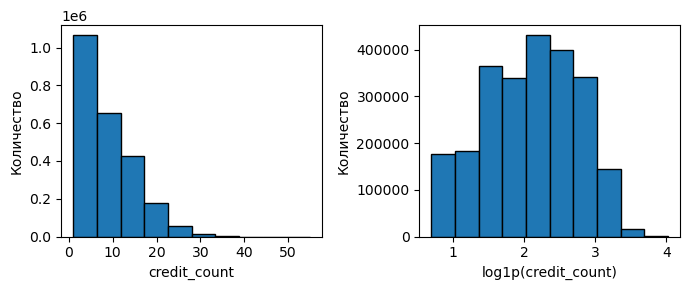

In [71]:
credit_count = X_train['credit_count']
log1p_credit_count = np.log1p(credit_count)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))

axes[0].hist(credit_count, ec='black')
axes[0].set_xlabel('credit_count')
axes[0].set_ylabel('Количество')

axes[1].hist(log1p_credit_count, ec='black')
axes[1].set_xlabel('log1p(credit_count)')
axes[1].set_ylabel('Количество')

fig.tight_layout()

Распределение `credit_count` имеет длинный правый хвост. Преобразование `log1p` уменьшает различия между большими значениями и делает распределение более симметричным. Проверим два варианта использования `log1p(credit_count)`: в дополнение к исходному признаку и вместо него.

In [72]:
X_train_1 = X_train.copy()
X_train_1['log1p(credit_count)'] = log1p_credit_count

X_train_2 = X_train_1.copy()
X_train_2 = X_train_2.drop(columns='credit_count')

In [73]:
validate(
    torch_mlp_opt_pipe, X_train_1, y_train, skf,
    n_jobs=1, pre_dispatch=1
);
# Освобождаем память
del X_train_1, credit_count, log1p_credit_count

Модель: Pipeline with TorchMLPClassifier


Training:  40%|████████████████████▍                              | 6/15 [01:23<02:04, 13.88s/epoch]


[CV] END ................................ score: (test=0.762) total time= 1.7min


Training:  33%|█████████████████                                  | 5/15 [01:11<02:22, 14.21s/epoch]


[CV] END ................................ score: (test=0.765) total time= 1.5min


Training:  40%|████████████████████▍                              | 6/15 [01:23<02:05, 13.94s/epoch]


[CV] END ................................ score: (test=0.764) total time= 1.7min
Продолжительность валидации: 4.9 мин
ROC-AUC mean: 0.7636
ROC-AUC std:  0.0011


После добавления `log1p(credit_count)` средний ROC-AUC вырос с 0.7627 до 0.7636. Прирост 0.0009 сопоставим со СКО оценок по фолдам, которое составило 0.0011. Теперь проверим вариант без исходного признака `credit_count`.

In [74]:
validate(
    torch_mlp_opt_pipe, X_train_2, y_train, skf,
    n_jobs=1, pre_dispatch=1
);

Модель: Pipeline with TorchMLPClassifier


Training:  40%|████████████████████▍                              | 6/15 [01:23<02:05, 13.91s/epoch]


[CV] END ................................ score: (test=0.762) total time= 1.7min


Training:  33%|█████████████████                                  | 5/15 [01:11<02:23, 14.36s/epoch]


[CV] END ................................ score: (test=0.764) total time= 1.5min


Training:  47%|███████████████████████▊                           | 7/15 [01:35<01:49, 13.70s/epoch]


[CV] END ................................ score: (test=0.764) total time= 1.9min
Продолжительность валидации: 5.1 мин
ROC-AUC mean: 0.7634
ROC-AUC std:  0.0011


Без исходного `credit_count` средний ROC-AUC составил 0.7634 против 0.7636 при обоих признаках. Пренебрежём разницей 0.0002 и удалим исходный признак.

## 4.3 Флаги для агрегированных бинарных признаков

In [75]:
binary_features = [
    'is_zero_loans5',
    'is_zero_loans530',
    'is_zero_loans3060',
    'is_zero_loans6090',
    'is_zero_loans90',
    'is_zero_util',
    'is_zero_over2limit',
    'is_zero_maxover2limit',
    'pclose_flag',
    'fclose_flag',
]

In [76]:
X_train_3 = X_train_2.copy()

for feature in binary_features:
    X_train_3[f'{feature}_flag'] = (X_train_3[feature] > 0).astype('uint8')

In [77]:
validate(
    torch_mlp_opt_pipe, X_train_3, y_train, skf,
    n_jobs=1, pre_dispatch=1
);
del X_train_3  # освобождаем память

Модель: Pipeline with TorchMLPClassifier


Training:  40%|████████████████████▍                              | 6/15 [01:24<02:06, 14.02s/epoch]


[CV] END ................................ score: (test=0.762) total time= 1.7min


Training:  47%|███████████████████████▊                           | 7/15 [01:35<01:49, 13.70s/epoch]


[CV] END ................................ score: (test=0.763) total time= 1.9min


Training:  47%|███████████████████████▊                           | 7/15 [01:35<01:49, 13.69s/epoch]


[CV] END ................................ score: (test=0.764) total time= 1.9min
Продолжительность валидации: 5.5 мин
ROC-AUC mean: 0.7631
ROC-AUC std:  0.0008


При добавлении флагов средний ROC-AUC составил 0.7631 против 0.7634 без них. Добавление флагов не улучшило результат, поэтому продолжим работу без них.

## 4.4 Признаки с маленьким количеством ненулевых значений

In [78]:
threshold = 100000

nonzero_count = (X_train_2 != 0).sum()
rare_features = nonzero_count[nonzero_count < threshold].index

X_train_4 = X_train_2.drop(columns=rare_features)

print('Количество удалённых признаков:', len(rare_features))

validate(
    torch_mlp_opt_pipe, X_train_4, y_train, skf,
    n_jobs=1, pre_dispatch=1
);
del X_train_4  # освобождаем память

Количество удалённых признаков: 130
Модель: Pipeline with TorchMLPClassifier


Training:  40%|████████████████████▍                              | 6/15 [01:22<02:03, 13.76s/epoch]


[CV] END ................................ score: (test=0.762) total time= 1.6min


Training:  40%|████████████████████▍                              | 6/15 [01:21<02:02, 13.65s/epoch]


[CV] END ................................ score: (test=0.763) total time= 1.6min


Training:  40%|████████████████████▍                              | 6/15 [01:22<02:03, 13.71s/epoch]


[CV] END ................................ score: (test=0.764) total time= 1.6min
Продолжительность валидации: 4.7 мин
ROC-AUC mean: 0.7631
ROC-AUC std:  0.0005


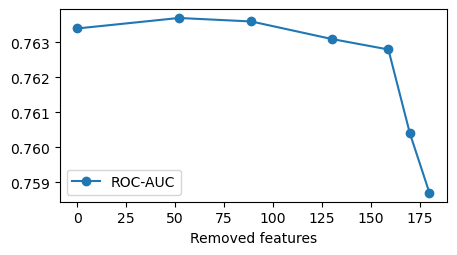

,Threshold,Removed features,ROC-AUC
0,0,0,0.7634
1,1000,52,0.7637
2,10000,89,0.7636
3,100000,130,0.7631
4,300000,159,0.7628
5,400000,170,0.7604
6,500000,180,0.7587


In [79]:
data = [
    [0, 0, 0.7634],
    [1000, 52, 0.7637],
    [10000, 89, 0.7636],
    [100000, 130, 0.7631],
    [300000, 159, 0.7628],
    [400000, 170, 0.7604],
    [500000, 180, 0.7587],
]
results = pd.DataFrame(
    data,
    columns=[
        'Threshold',
        'Removed features',
        'ROC-AUC'
    ]
)
results.plot(
    x='Removed features',
    y='ROC-AUC',
    style='o-',
    figsize=(5, 2.5)
);
plt.show()
results

Наибольший средний ROC-AUC получен при удалении 52 признаков — 0.7637 против 0.7634 без удаления. Прирост 0.0003 сочтём пренебрежимым. При удалении 130 признаков ROC-AUC составил 0.7631, а валидация заняла 4.7 мин вместо 5.1 мин. Дальнейшее сокращение набора признаков снижает ROC-AUC. Выигрыш во времени невелик, поэтому продолжим работу без удаления редких признаков.

## 4.5 Количество уникальных значений категориальных признаков

In [80]:
X_train_5 = X_train_2.copy()
del X_train_2  # освобождаем память

for feature in categorical_features:
    cols = [
        col for col in X_train_5.columns
        if col.startswith(f'{feature}_')
    ]
    X_train_5[f'{feature}_nunique'] = (
        (X_train_5[cols] > 0)
        .sum(axis=1)
        .astype('uint8')
    )

In [81]:
torch_mlp_opt_fe_auc, _ = validate(
    torch_mlp_opt_pipe, X_train_5, y_train, skf,
    n_jobs=1, pre_dispatch=1
);

Модель: Pipeline with TorchMLPClassifier


Training:  40%|████████████████████▍                              | 6/15 [01:23<02:05, 13.97s/epoch]


[CV] END ................................ score: (test=0.763) total time= 1.7min


Training:  33%|█████████████████                                  | 5/15 [01:12<02:24, 14.41s/epoch]


[CV] END ................................ score: (test=0.766) total time= 1.5min


Training:  47%|███████████████████████▊                           | 7/15 [01:35<01:49, 13.71s/epoch]


[CV] END ................................ score: (test=0.765) total time= 1.9min
Продолжительность валидации: 5.2 мин
ROC-AUC mean: 0.7647
ROC-AUC std:  0.0013


После добавления количества уникальных значений категориальных признаков средний ROC-AUC вырос с 0.7634 до 0.7647 — примерно на величину СКО оценок по фолдам. Сохраним добавленные признаки и завершим на этом конструирование признаков.

## 4.6 Итоговый FunctionTransformer

In [82]:
def engineer_features(X, categorical_features):
    X = X.copy()

    X['log1p(credit_count)'] = (
        np.log1p(X['credit_count']).astype('float32')
    )
    X = X.drop(columns='credit_count')

    for feature in categorical_features:
        cols = [
            col for col in X.columns
            if col.startswith(f'{feature}_')
        ]
        X[f'{feature}_nunique'] = (
            (X[cols] > 0).sum(axis=1).astype('uint8')
        )

    return X

In [83]:
feature_engineer = FunctionTransformer(
    engineer_features,
    kw_args={'categorical_features': categorical_features}
)

Проверим, что `FunctionTransformer` воспроизводит набор признаков, полученный в предыдущих экспериментах.

In [84]:
X_train_final = feature_engineer.fit_transform(X_train)
X_train_final.equals(X_train_5)

True

In [85]:
del X_train_final, X_train_5  # освобождаем память

# 5 Повторное сравнение моделей после конструирования признаков

In [86]:
lr_opt_fe_pipe = Pipeline([
    ('feature_engineering', feature_engineer),
    ('scaler', StandardScaler()),
    ('model', lr_opt)
])

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

lr_opt_fe_auc, _ = validate(
    lr_opt_fe_pipe, X_train, y_train, skf, n_jobs=1, pre_dispatch=1
)

Модель: Pipeline with LogisticRegression
[CV] END ................................ score: (test=0.748) total time= 1.4min
[CV] END ................................ score: (test=0.751) total time= 1.5min
[CV] END ................................ score: (test=0.747) total time= 1.3min
Продолжительность валидации: 4.2 мин
ROC-AUC mean: 0.7486
ROC-AUC std:  0.0015


In [87]:
rf_opt_fe_pipe = Pipeline([
    ('feature_engineering', feature_engineer),
    ('model', rf_opt)
])

rf_opt_fe_auc, _ = validate(
    rf_opt_fe_pipe, X_train, y_train, skf,
    n_jobs=1, pre_dispatch=1
)

Модель: Pipeline with RandomForestClassifier
[CV] END ................................ score: (test=0.747) total time=10.9min
[CV] END ................................ score: (test=0.751) total time=11.0min
[CV] END ................................ score: (test=0.748) total time=10.9min
Продолжительность валидации: 32.8 мин
ROC-AUC mean: 0.7489
ROC-AUC std:  0.0016


In [88]:
mlp_opt_fe_pipe = Pipeline([
    ('feature_engineering', feature_engineer),
    ('scaler', StandardScaler()),
    ('model', mlp_opt)
])

mlp_opt_fe_auc, _ = validate(
    mlp_opt_fe_pipe, X_train, y_train, skf,
    n_jobs=1, pre_dispatch=1
)

Модель: Pipeline with MLPClassifier
[CV] END ................................ score: (test=0.761) total time= 1.6min
[CV] END ................................ score: (test=0.751) total time= 1.6min
[CV] END ................................ score: (test=0.760) total time= 1.6min
Продолжительность валидации: 4.8 мин
ROC-AUC mean: 0.7571
ROC-AUC std:  0.0043


In [89]:
pd.DataFrame(
    np.round([
        [lr_opt_auc, lr_opt_fe_auc],
        [rf_opt_auc, rf_opt_fe_auc],
        [mlp_opt_auc, mlp_opt_fe_auc],
        [torch_mlp_opt_auc, torch_mlp_opt_fe_auc]
    ], 4),
    index=pd.Index([
        'LogisticRegression',
        'RandomForestClassifier',
        'MLPClassifier',
        'TorchMLPClassifier',
    ], name='Model'),
    columns=pd.MultiIndex.from_product([
        ['ROC-AUC'],
        ['Before FE', 'After FE'],
    ])
)

ROC-AUC         
                       Before FE After FE
Model                                    
LogisticRegression        0.7342   0.7486
RandomForestClassifier    0.7469   0.7489
MLPClassifier             0.7478   0.7571
TorchMLPClassifier        0.7547   0.7647

После конструирования признаков средний ROC-AUC вырос у всех четырёх моделей. Лучший результат по-прежнему у `TorchMLPClassifier` — 0.7647. Перейдём к его финальной настройке на выбранном наборе признаков.

# 6 Финальная настройка лучшей модели

In [90]:
# Чтобы можно было пропустить поиск по сетке

best_torch_mlp_params = {
    'batch_size': 4096,
    'hidden_layer_sizes': (256, 128),
    'learning_rate': 0.002,
    'weight_decay': 0.0001
}

In [91]:
torch_mlp_opt = TorchMLPClassifier(
    device=device,
    random_state=42,
    verbose=True,
    use_pos_weight=True,
    early_stopping=True,
    patience=3,
    max_epochs=15,
    **best_torch_mlp_params,
)

torch_mlp_opt_fe_pipe = Pipeline([
    ('feature_engineering', feature_engineer),
    ('scaler', StandardScaler()),
    ('model', torch_mlp_opt)
])

## 6.1 Подбор функции активации и скорости обучения

Сравним `ReLU`, `LeakyReLU` и `Tanh` при `learning_rate=0.001` и `0.002`. Проверим эти параметры совместно, поскольку подходящая скорость обучения может зависеть от функции активации. Остальные гиперпараметры оставим прежними. Для выбора используем средний ROC-AUC на 3-кратной стратифицированной кросс-валидации.

In [92]:
%%time

param_grid = {
    'model__activation': [
        'relu',
        'leaky_relu',
        'tanh',
    ],
    'model__learning_rate': [
        0.001,
        0.002,
    ],
}

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

torch_mlp_opt_fe_pipe_gs = GridSearchCV(
    estimator=torch_mlp_opt_fe_pipe,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=skf,
    n_jobs=1,
    pre_dispatch=1,
    verbose=3,
    refit=False,
)

torch_mlp_opt_fe_pipe_gs.fit(X_train, y_train);

Fitting 3 folds for each of 6 candidates, totalling 18 fits


Training:  40%|████████████████████▍                              | 6/15 [01:23<02:05, 13.95s/epoch]


[CV 1/3] END model__activation=relu, model__learning_rate=0.001;, score=0.764 total time= 1.9min


Training:  33%|█████████████████                                  | 5/15 [01:12<02:24, 14.44s/epoch]


[CV 2/3] END model__activation=relu, model__learning_rate=0.001;, score=0.767 total time= 1.7min


...

[CV 1/3] END model__activation=tanh, model__learning_rate=0.002;, score=0.759 total time= 1.9min


Training:  47%|███████████████████████▊                           | 7/15 [01:36<01:50, 13.85s/epoch]


[CV 2/3] END model__activation=tanh, model__learning_rate=0.002;, score=0.760 total time= 2.1min


Training:  47%|███████████████████████▊                           | 7/15 [01:36<01:50, 13.85s/epoch]


[CV 3/3] END model__activation=tanh, model__learning_rate=0.002;, score=0.761 total time= 2.1min
CPU times: total: 2h 46min 36s
Wall time: 34min 32s


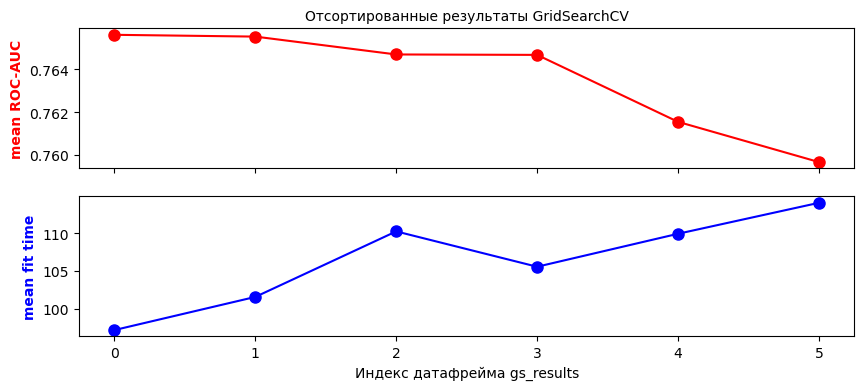

,model__activation,model__learning_rate,rank_test_score,mean_test_score,mean_fit_time
0,relu,0.001,1,0.765614,97.160116
1,leaky_relu,0.001,2,0.765530,101.558999
2,leaky_relu,0.002,3,0.764695,110.255666
3,relu,0.002,4,0.764675,105.564009
4,tanh,0.001,5,0.761546,109.939111
5,tanh,0.002,6,0.759664,114.048666


In [93]:
torch_mlp_opt_fe_pipe_gs_results = (
    visualize_gs_results(torch_mlp_opt_fe_pipe_gs)
)
torch_mlp_opt_fe_pipe_gs_results

При `learning_rate=0.001` средний ROC-AUC выше, чем при `0.002`, для всех трёх функций активации. Лучший результат получен с `ReLU` — 0.7656. Разница с `LeakyReLU` пренебрежима, а `Tanh` уступает обеим функциям при каждой из проверенных скоростей обучения. Сохраним `activation='relu'` и выберем `learning_rate=0.001` для дальнейшей настройки.

In [94]:
torch_mlp_opt_fe_pipe_best_params_1 = torch_mlp_opt_fe_pipe_gs.best_params_
torch_mlp_opt_fe_pipe_best_params_1

{'model__activation': 'relu', 'model__learning_rate': 0.001}

In [95]:
# Чтобы можно было пропустить поиск по сетке

# torch_mlp_opt_fe_pipe_best_params_1 = {
#     'model__activation': 'relu', 'model__learning_rate': 0.001
# }

In [96]:
torch_mlp_opt_fe_pipe.set_params(
    **torch_mlp_opt_fe_pipe_best_params_1
);

## 6.2 Подбор размеров скрытых слоёв и регуляризации

Сравним размеры скрытых слоёв `(128, 64)` и `(256, 128)` при `learning_rate=0.001` и `0.0005`. Для каждой комбинации проверим три варианта регуляризации: отключённую (`weight_decay=0`), с ранее выбранным значением `1e-4` и усиленную до `1e-3`. Функцию активации `ReLU` и остальные гиперпараметры оставим прежними. Все 12 комбинаций оценим на 3-кратной стратифицированной кросс-валидации.

In [97]:
%%time

param_grid = {
    'model__hidden_layer_sizes': [(128, 64), (256, 128)],
    'model__learning_rate': [0.001, 0.0005],
    'model__weight_decay': [0, 1e-4, 1e-3],
}

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

torch_mlp_opt_fe_pipe_gs = GridSearchCV(
    estimator=torch_mlp_opt_fe_pipe,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=skf,
    n_jobs=1,
    pre_dispatch=1,
    verbose=3,
    refit=False,
)

torch_mlp_opt_fe_pipe_gs.fit(X_train, y_train);

Fitting 3 folds for each of 12 candidates, totalling 36 fits


Training:  40%|████████████████████▍                              | 6/15 [01:18<01:57, 13.02s/epoch]


[CV 1/3] END model__hidden_layer_sizes=(128, 64), model__learning_rate=0.001, model__weight_decay=0;, score=0.765 total time= 1.8min


Training:  33%|█████████████████                                  | 5/15 [01:10<02:20, 14.08s/epoch]


[CV 2/3] END model__hidden_layer_sizes=(128, 64), model__learning_rate=0.001, model__weight_decay=0;, score=0.767 total time= 1.7min


...

[CV 1/3] END model__hidden_layer_sizes=(256, 128), model__learning_rate=0.0005, model__weight_decay=0.001;, score=0.764 total time= 1.7min


Training:  33%|█████████████████                                  | 5/15 [01:05<02:11, 13.18s/epoch]


[CV 2/3] END model__hidden_layer_sizes=(256, 128), model__learning_rate=0.0005, model__weight_decay=0.001;, score=0.766 total time= 1.6min


Training:  47%|███████████████████████▊                           | 7/15 [01:28<01:40, 12.60s/epoch]


[CV 3/3] END model__hidden_layer_sizes=(256, 128), model__learning_rate=0.0005, model__weight_decay=0.001;, score=0.766 total time= 1.9min
CPU times: total: 5h 1min 44s
Wall time: 1h 3min


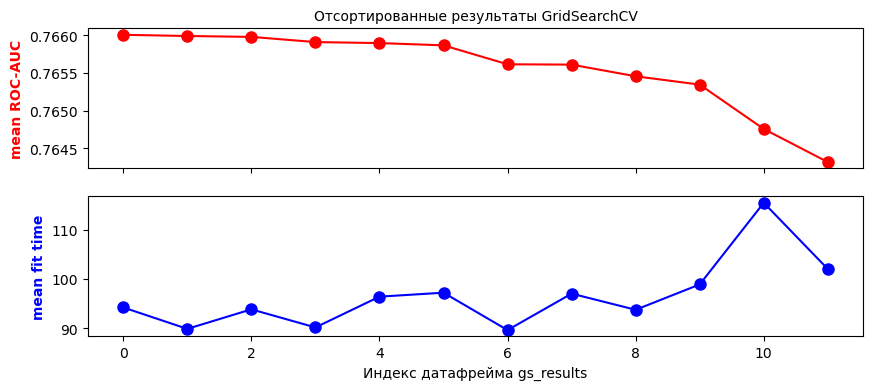

,model__hidden_layer_sizes,model__learning_rate,model__weight_decay,rank_test_score,mean_test_score,mean_fit_time
0,"(128, 64)",0.0005,0.0001,1,0.766005,94.223853
1,"(256, 128)",0.0005,0.0001,2,0.765989,89.859994
2,"(128, 64)",0.0005,0.0000,3,0.765978,93.840906
3,"(256, 128)",0.0005,0.0000,4,0.765909,90.154654
4,"(128, 64)",0.0010,0.0001,5,0.765895,96.423667
5,"(128, 64)",0.0010,0.0000,6,0.765866,97.229985
6,"(256, 128)",0.0010,0.0001,7,0.765614,89.615010
7,"(256, 128)",0.0005,0.0010,8,0.765610,97.037707
8,"(256, 128)",0.0010,0.0000,9,0.765455,93.748781
9,"(128, 64)",0.0005,0.0010,10,0.765345,98.914601


In [98]:
torch_mlp_opt_fe_pipe_gs_results = (
    visualize_gs_results(torch_mlp_opt_fe_pipe_gs)
)
torch_mlp_opt_fe_pipe_gs_results

In [99]:
torch_mlp_opt_fe_pipe_best_params_2 = torch_mlp_opt_fe_pipe_gs.best_params_
torch_mlp_opt_fe_pipe_best_params_2

{'model__hidden_layer_sizes': (128, 64),
 'model__learning_rate': 0.0005,
 'model__weight_decay': 0.0001}

При `learning_rate=0.0005` средний ROC-AUC выше, чем при `0.001`, во всех проверенных сочетаниях размеров скрытых слоёв и регуляризации. Преимущество `weight_decay=1e-4` перед отключённой регуляризацией пренебрежимо, а увеличение до `1e-3` снижает качество. Лучший результат — 0.7660 — получен при `hidden_layer_sizes=(128, 64)`, `learning_rate=0.0005` и `weight_decay=1e-4`. Более крупная сеть при тех же остальных параметрах даёт практически такой же результат.

Чтобы не расширять сетку, лучшая конфигурация проверена отдельно при `learning_rate=0.00025`. Этот код не сохранён в итоговом ноутбуке. Средний ROC-AUC составил 0.7656 против 0.7660 при `learning_rate=0.0005`.

Выберем лучшую конфигурацию и завершим подбор гиперпараметров.

In [100]:
# Чтобы можно было пропустить поиск по сетке

# torch_mlp_opt_fe_pipe_best_params_2 = {
#     'model__hidden_layer_sizes': (128, 64),
#     'model__learning_rate': 0.0005,
#     'model__weight_decay': 0.0001
# }

In [101]:
torch_mlp_opt_fe_pipe.set_params(
    **torch_mlp_opt_fe_pipe_best_params_2
);

# 7 Оценка модели

Обучим модель с выбранными гиперпараметрами на всей обучающей выборке и оценим ROC-AUC на тестовой. Проверим, выполнено ли требование ROC-AUC ≥ 0.75.

In [102]:
%%time
torch_mlp_opt_fe_pipe.fit(X_train, y_train)
del X_train, y_train  # освобождаем память

Training:  47%|███████████████████████▊                           | 7/15 [02:26<02:47, 20.99s/epoch]


CPU times: total: 15min 4s
Wall time: 2min 58s


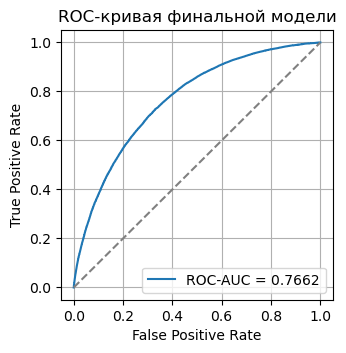

In [103]:
predict_proba = torch_mlp_opt_fe_pipe.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, predict_proba)

fpr, tpr, _ = roc_curve(y_test, predict_proba)

fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.plot(fpr, tpr, label=f'ROC-AUC = {test_auc:.4f}')
ax.plot([0, 1], [0, 1], '--', color='gray')
ax.set(
    xlabel='False Positive Rate',
    ylabel='True Positive Rate',
    title='ROC-кривая финальной модели'
)
ax.grid()
ax.legend()
plt.show()

На тестовой выборке ROC-AUC составил 0.7662. Требование ROC-AUC ≥ 0.75 выполнено.

# 8 Финальное обучение и сохранение результатов

Сохраним предсказания на тестовой выборке, затем повторно обучим выбранный пайплайн на полном наборе данных, включая тестовую часть. Сохраним обученный пайплайн и проверим, что после загрузки из файла его предсказания совпадают с исходными. На вход пайплайна подаются данные, агрегированные по схеме подраздела 4.1.

In [104]:
# Сохраняем предсказания на тестовой выборке

test_predictions = pd.DataFrame({
    'id': X_test.index,
    'score': predict_proba,
})

test_predictions.to_csv(
    'test_predictions.csv',
    index=False
)

# Освобождаем память
del X_test, y_test, predict_proba, test_predictions

In [105]:
# Обучаем финальный пайплайн на всём датасете

prepared_dataset_weighted = pd.read_parquet(
    'train_data/prepared_dataset_weighted.pq'
)

y_full = prepared_dataset_weighted.pop('flag')
X_full = prepared_dataset_weighted

torch_mlp_opt_fe_pipe.fit(X_full, y_full)

# Переносим обученную модель на CPU перед сохранением,
# чтобы пайплайн не зависел от наличия CUDA при инференсе
model = torch_mlp_opt_fe_pipe.named_steps['model']
model.model_.to('cpu')
model.device = 'cpu'

# Сохраняем пайплайн
with open('credit_risk_pipeline.pkl', 'wb') as file:
    pickle.dump(torch_mlp_opt_fe_pipe, file)

Training:  40%|████████████████████▍                              | 6/15 [02:40<04:01, 26.79s/epoch]


In [106]:
# Готовимся к проверке загрузки пайплайна из файла

X_check = X_full.sample(n=1000, random_state=42).copy()
predict_proba_check = torch_mlp_opt_fe_pipe.predict_proba(X_check)[:, 1]

X_check.to_parquet('X_check.pq')
np.save('predict_proba_check.npy', predict_proba_check)

# Освобождаем память
del prepared_dataset_weighted, X_full, y_full

In [107]:
# Проверяем загрузку пайплайна из файла

# Поскольку X_check и predict_proba_check сохранены в файлы,
# проверку загрузки пайплайна можно выполнить после перезапуска ядра.
# Перед проверкой нужно выполнить только импорты и определения
# CreditRiskMLP, TorchMLPClassifier и engineer_features.

with open('credit_risk_pipeline.pkl', 'rb') as file:
    loaded_pipeline = pickle.load(file)

X_check = pd.read_parquet('X_check.pq')
predict_proba_check = np.load('predict_proba_check.npy')
loaded_predict_proba = loaded_pipeline.predict_proba(X_check)[:, 1]

predictions_match = np.allclose(
    predict_proba_check,
    loaded_predict_proba
)
print(
    'Загруженный пайплайн даёт такие же предсказания: '
    f'{predictions_match}'
)

Загруженный пайплайн даёт такие же предсказания: True


# 9 Заключение

Лучший результат среди рассмотренных моделей показал многослойный перцептрон на PyTorch. После конструирования признаков и подбора гиперпараметров ROC-AUC на тестовой выборке составил 0.7662, что превышает требуемый уровень 0.75.

Для представления кредитной истории использована агрегация с весами, пропорциональными `rn` и нормированными на их сумму. В итоговый набор признаков включены `log1p(credit_count)` и количества уникальных значений категориальных признаков. Эти изменения повысили средний ROC-AUC выбранной модели на кросс-валидации с 0.7547 до 0.7647. Финальный подбор гиперпараметров повысил его до 0.7660.

Подготовка признаков, масштабирование и модель объединены в совместимый со scikit-learn пайплайн. После оценки качества пайплайн повторно обучен на полном наборе данных и сохранён. Проверка подтвердила совпадение предсказаний до и после загрузки из файла.

Требуемое качество достигнуто, поэтому не будем продолжать эксперименты. Возможные направления улучшения — нелинейная зависимость весов от `rn`, усиливающая вклад последних кредитных продуктов, и отдельные признаки последнего кредита. Первый вариант не увеличивает число признаков, а во втором можно ограничиться частью характеристик, чтобы сдержать рост размерности. Пользу этих изменений необходимо проверять экспериментально.